# NB baseline on the log1p PhiSpace table

Specification tests for the division-count model, rerun on the rebuilt table
(`data/mixture_cells_major.parquet`): PhiSpace refitted on log1p-normalised
expression, and cells with library size $N < 10$ dropped, leaving 561,897
cells. Every test in `exploration.ipynb` ran on the SpaNorm-based scores, which
turned out to be about 86% sequencing depth, and on an oxygen field whose
source did not mark vessels. None of those conclusions carries over without a
rerun, which is what this notebook does.

**The model.** Throughout, the *baseline NB* is the production mixture's
covariates placed in a single negative-binomial mean, with the mixture's
penalty (`src/tissue_dynamics/nb_baseline.py`):

$$\log\mu_i = b_0 + \theta\log N_i + s(\log\text{area}_i) + \eta(x_i)$$

$$\eta(x) = \phi^\top a + \bar\phi^\top c + \sum_{r=1}^{3}(\phi^\top U_r)(\bar\phi^\top V_r) + H^\top h + \phi^\top K H$$

Here $\phi$ is the cell's own state, projected to 8 sum-to-zero coordinates.
$\bar\phi$ stacks two neighbour means: contact (typed cells within 15 µm) and
regional (15–80 µm), 8 coordinates each. Every block is whitened, so each
coordinate has unit variance. $H$ is a log-density
spline, and $K$ gives each cell type its own density curve. $\eta$ is the same
block as the mixture's mixing weight, so any test that changes $\eta$ here
(oxygen, the neighbourhood) informs the mixture directly. A fit on all cells
takes 4–9 minutes, against hours for the mixture's 20 restarts.

**Decisions already taken (2026-10-06)**, on the evidence in §2 and §3:
- $\theta$ is fixed at 1, so $\log N$ is an offset;
- the oxygen term $\psi\,u$ is dropped from every model (config
  `model.theta_free: false`, `model.oxygen: false`).

The baseline in §3–5 is therefore an offset model with no oxygen. §3 adds
oxygen back only to test it.

| § | test | question |
|---|---|---|
| 2 | depth: offset, free exponent, spline, per-type slopes; constant vs state-dependent dispersion | which baseline? |
| 3 | oxygen field: source validity, HIF markers, decoys, $L_0$ sweep | does vessel proximity explain division beyond cell state? |
| 4 | annulus test, naive and count-matched | is the neighbourhood effect real, or segmentation spillover? |
| 5 | neighbourhood structure: contact/regional split, ring stack, distance-decay kernels, spatial CV | how should $\bar\phi$ weight its neighbours? |
| 6 | summary | what to carry into the mixture |

**How evidence is read.** With about $5\times10^5$ cells every term is
"significant", so p-values decide nothing here. The evidence is:
- calibration (rootogram, PIT), not likelihood alone;
- *decoys*, the same field rotated or mirrored, as the null for any smooth
  spatial covariate;
- effect sizes compared across specifications.

Standard errors are model-based and ignore spatial autocorrelation, so they are
too small. Read them as relative, not absolute.

**Weight model and penalty.** Everything here uses the final weight model
(decided 2026-10-07): the contact/regional split, whitened blocks, $B$ penalised
by $\lambda\lVert UV^\top\rVert_F^2$ plus the balance term
$\tau\lVert U^\top U - V^\top V\rVert_F^2$, $\lambda = 300$, rank 3. The first
version of this notebook (2026-10-06) ran under the earlier weight model: the
80 µm disc, unwhitened blocks, the nuclear norm, $\lambda = 10$, rank 2. Its
fits are kept in `outputs/nb_baseline/cache/pinned_2026-10-06/`, and where a
conclusion changed, the readings say so.

Heavy results (fits, PDE solves, ring sums) are cached in
`outputs/nb_baseline/cache/`, which is gitignored. Delete a file there to
recompute it. Run cold, the notebook takes about three hours; from the cache it
takes about a minute.

In [1]:
import os, sys, json, time, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import roc_auc_score
from tissue_dynamics import nb_baseline as nbb
from tissue_dynamics.annulus import spillover_chi2
from tissue_dynamics.mixture.data import load_config

pd.set_option("display.width", 170, "display.max_columns", 30, "display.precision", 4)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "font.size": 9.5, "axes.titlesize": 10.5})
INK, MUTED = "#0b0b0b", "#8a8984"
COL = {"real": "#2a78d6", "decoy": "#eb6834", "base": "#52514e", "alt": "#1baf7a"}
OUT = Path("outputs/nb_baseline"); OUT.mkdir(parents=True, exist_ok=True)

def savefig(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=150, bbox_inches="tight")

cfg = load_config()                   # the production weight model, as configured
df, basis, spec, D = nbb.load_design(cfg)
PEN = dict(weight_ridge=spec.weight_ridge, n_reference=spec.n_reference, ridge_tau=spec.ridge_tau,
           b_penalty=spec.b_penalty, rank=spec.rank)
y = D["y"]; n = len(y)
TYPES = list(basis.own_names)
ctype = df["archetype"].astype(str).to_numpy()
xc, yc = df["x"].to_numpy(), df["y"].to_numpy()
logN = np.log(df["N"].to_numpy(float))
T_all = nbb.tiles(xc, yc)

print(f"{n:,} cells | mean count {y.mean():.3f} | var/mean {y.var() / y.mean():.2f} | "
      f"zeros {100 * np.mean(y == 0):.1f}%")
print(f"design: own {D['own'].shape[1]} coords (from {len(TYPES)} types), nbr {D['nbr'].shape[1]}, "
      f"area spline {D['area'].shape[1]}, density spline {D['hbasis'].shape[1]}, rank {spec.rank}")
print(f"weight model: {cfg['state']['neighbourhood']} neighbourhood, whitened {cfg['state']['whiten']}, "
      f"{spec.b_penalty} penalty on B, weight_ridge {spec.weight_ridge:g} x n / {spec.n_reference:,}, "
      f"balance tau {spec.ridge_tau:g}")
print(f"{T_all['keep'].sum():,} tiles of 100 um with >= 5 cells, for residual Moran's I")
pd.Series(ctype).value_counts().rename("cells (standardised argmax)").to_frame().T

561,897 cells | mean count 1.041 | var/mean 7.72 | zeros 62.2%
design: own 8 coords (from 9 types), nbr 16, area spline 7, density spline 5, rank 3
weight model: split neighbourhood, whitened True, frobenius penalty on B, weight_ridge 300 x n / 678,885, balance tau 1
10,481 tiles of 100 um with >= 5 cells, for residual Moran's I


,Cancer Epithelial,T-cells,Myeloid,B-cells,Normal Epithelial,CAFs,Endothelial,Plasmablasts,PVL
cells (standardised argmax),110805,89213,68186,57825,53149,52506,47810,42228,40175


## 2. Choosing the baseline: depth and dispersion

Two specification choices from the old notebook are retested here.

**Depth: is the offset right?** With $\theta$ fixed at 1, $\log N$ is an offset
and the model is a *rate* model: state effects read "per transcript captured".
That is the production choice. The old notebook's §21 found
$\theta \approx 0.70$, with depth measured as total counts. The SpaNorm table
gave $\theta = -0.25$, a symptom of its artefact: the depth signal was split
between $\log N$ and the depth-laden state scores. Here $N$ excludes the Tirosh
genes and the blocklist, and the area spline is in the model.

The offset is tested four ways, because a single free exponent only asks
whether the *average* slope is 1:
1. a free exponent $\theta$;
2. the offset plus a natural spline in $\log N$ (5 df), which lets the depth
   response bend anywhere in its range;
3. the offset plus per-cell-type slope deviations,
   $(\phi_i^\top t)(\log N_i - \overline{\log N})$ (8 df);
4. observed over expected counts by decile of depth.

**Dispersion: constant or state-dependent?** The alternative is
$\log\alpha_i = \gamma_0 + \phi_i^\top\gamma$, the old §24 submodel and the
division comparison's NB-d. Both variants are fit by joint penalised maximum
likelihood. The constant-$\alpha$ row is therefore an honest baseline, and the
old notebook's moment-estimator comparison does not arise.

The four depth-by-dispersion combinations, plus the two extra depth models,
are all fit on all 561,897 cells. The criteria, in order:
1. calibration: rootogram misfit and PIT;
2. residual Moran's I;
3. likelihood per parameter.

In [2]:
GRID = [(th, disp) for th in ("offset", "free") for disp in ("const", "state")]
tune = {key: nbb.cached(f"tune_{key[0]}_{key[1]}",
                        lambda key=key: nbb.fit(D, theta=key[0], dispersion=key[1], say=print, **PEN))
        for key in GRID}
depth_fits = {th: nbb.cached(f"tune_{th}_const", lambda th=th: nbb.fit(
                  D, theta=th, dispersion="const", init=tune[("offset", "const")]["params"],
                  say=print, **PEN))
              for th in ("spline", "by_type")}
roots = {key: nbb.rootogram(y, f["mu"], f["alpha"]) for key, f in tune.items()}

rows = []
for key, f in tune.items():
    r = nbb.summarise(f, y, T_all)
    r["theta_se"] = float(np.sqrt(nbb.estimate(f, "theta")[1][0, 0])) if key[0] == "free" else np.nan
    rows.append({"depth": key[0], "dispersion": key[1], **r})
for th, f in depth_fits.items():
    rows.append({"depth": th, "dispersion": "const", **nbb.summarise(f, y, T_all), "theta_se": np.nan})
tune_tab = pd.DataFrame(rows).set_index(["depth", "dispersion"])
tune_tab.to_csv(OUT / "tuning.csv")
tune_tab[["k", "loglik", "theta", "theta_se", "alpha", "rootogram_misfit", "worst_bin",
          "worst_count", "pit_maxdev", "resid_moran", "converged", "minutes"]]

k       loglik   theta  theta_se   alpha  rootogram_misfit  worst_bin  worst_count  pit_maxdev  resid_moran  converged  minutes
depth   dispersion                                                                                                                                   
offset  const       150 -596377.0320  1.0000       NaN  0.7449          929.7977    15.6135            1      0.0466       0.0746       True   9.0659
        state       158 -596235.5613  1.0000       NaN  0.7303          865.0932    14.6575            1      0.0510       0.0742       True   7.3757
free    const       151 -596363.4980  1.0213    0.0041  0.7437          944.6086    16.0165            1      0.0454       0.0749       True   9.7361
        state       159 -596224.7724  1.0191    0.0041  0.7292          877.9514    15.0259            1      0.0496       0.0746       True   6.2164
spline  const       155 -595806.1701  1.0000       NaN  0.7352          651.1635    14.1981            1      0.0453       0.0747       True   6.3585
by_type const       158 -595627.6358  1.0000       NaN  0.7343          901.5857    14.9913            1      0.0463       0.0767       True   3.9245

In [3]:
ALL = {**tune, ("spline", "const"): depth_fits["spline"], ("by_type", "const"): depth_fits["by_type"]}
def lr(a, b, df_):
    s = 2 * (ALL[b]["loglik"] - ALL[a]["loglik"])
    return dict(LR=s, df=df_, dAIC=2 * df_ - s, dBIC=df_ * np.log(n) - s)

pd.DataFrame({
    "depth spline vs offset":               lr(("offset", "const"), ("spline", "const"), D["Nbasis"].shape[1]),
    "per-type depth slopes vs offset":      lr(("offset", "const"), ("by_type", "const"), D["own"].shape[1]),
    "free theta vs offset, constant alpha": lr(("offset", "const"), ("free", "const"), 1),
    "free theta vs offset, state alpha":    lr(("offset", "state"), ("free", "state"), 1),
    "state alpha vs constant, offset":      lr(("offset", "const"), ("offset", "state"), 8),
    "state alpha vs constant, free theta":  lr(("free", "const"), ("free", "state"), 8),
}).T

,LR,df,dAIC,dBIC
depth spline vs offset,1141.7239,5.0,-1131.7239,-1075.5286
per-type depth slopes vs offset,1498.7924,8.0,-1482.7924,-1392.8798
"free theta vs offset, constant alpha",27.0680,1.0,-25.0680,-13.8290
"free theta vs offset, state alpha",21.5779,1.0,-19.5779,-8.3388
"state alpha vs constant, offset",282.9414,8.0,-266.9414,-177.0288
"state alpha vs constant, free theta",277.4513,8.0,-261.4513,-171.5387


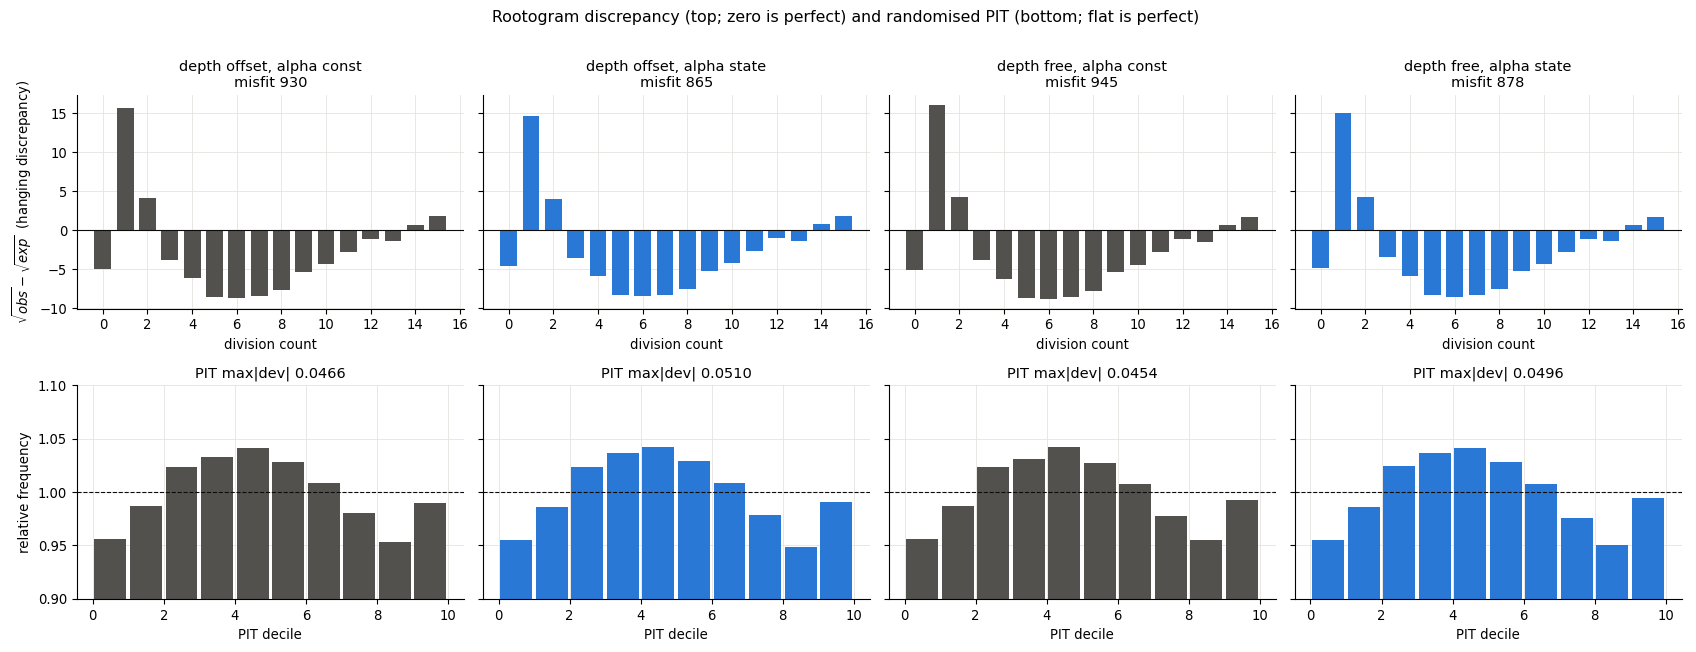

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(17, 6.4), sharey="row")
KS = np.arange(16)
for j, key in enumerate(GRID):
    obs, exp_ = roots[key]
    d = np.sqrt(obs) - np.sqrt(exp_)
    ax = axes[0, j]
    ax.bar(KS, d[:16], width=0.75, color=COL["real"] if key[1] == "state" else COL["base"])
    ax.axhline(0, color=INK, lw=0.8)
    ax.set_title(f"depth {key[0]}, alpha {key[1]}\nmisfit {tune_tab.loc[key, 'rootogram_misfit']:.0f}")
    ax.set_xlabel("division count")
    u = nbb.pit(y, tune[key]["mu"], tune[key]["alpha"])
    h = np.histogram(u, 10, (0, 1))[0] / (n / 10)
    ax = axes[1, j]
    ax.bar(np.arange(10) + 0.5, h, width=0.9, color=COL["real"] if key[1] == "state" else COL["base"])
    ax.axhline(1, color=INK, lw=0.8, ls="--"); ax.set_ylim(0.9, 1.1)
    ax.set_xlabel("PIT decile"); ax.set_title(f"PIT max|dev| {tune_tab.loc[key, 'pit_maxdev']:.4f}")
axes[0, 0].set_ylabel(r"$\sqrt{obs}-\sqrt{exp}$  (hanging discrepancy)")
axes[1, 0].set_ylabel("relative frequency")
fig.suptitle("Rootogram discrepancy (top; zero is perfect) and randomised PIT (bottom; flat is perfect)", y=1.01)
fig.tight_layout(); savefig(fig, "tuning_calibration")

In [5]:
# Do the state coefficients depend on the depth specification? (old §21's stability check)
eff = {key: pd.concat({"own": nbb.state_effects(tune[key], basis, "a"),
                       "nbr": nbb.state_effects(tune[key], basis, "c")}) for key in GRID}
a_, b_ = eff[("offset", "const")], eff[("free", "const")]
stab = a_.join(b_, lsuffix="_offset", rsuffix="_free")
stab["shift_in_se"] = (stab["estimate_free"] - stab["estimate_offset"]) / stab["se_offset"]
print(f"own + neighbour effects, offset vs free depth: Pearson r = "
      f"{np.corrcoef(stab['estimate_offset'], stab['estimate_free'])[0, 1]:.5f}, "
      f"largest shift {stab['shift_in_se'].abs().max():.2f} SE")
stab[["estimate_offset", "estimate_free", "z_offset", "z_free", "shift_in_se"]].round(3)

own + neighbour effects, offset vs free depth: Pearson r = 0.99975, largest shift 0.63 SE


estimate_offset  estimate_free  z_offset  z_free  shift_in_se
own Endothelial                          -0.307         -0.311   -26.531 -26.766       -0.344
    CAFs                                 -0.538         -0.540   -44.603 -44.757       -0.213
    PVL                                  -0.110         -0.110    -7.289  -7.277        0.009
    B-cells                               0.382          0.385    28.563  28.730        0.252
    T-cells                               0.397          0.400    43.495  43.690        0.351
    Myeloid                              -0.241         -0.240   -25.180 -24.975        0.175
    Normal Epithelial                    -0.155         -0.160   -12.810 -13.160       -0.408
    Plasmablasts                          0.111          0.114     6.656   6.876        0.235
    Cancer Epithelial                     0.462          0.462    41.283  41.186       -0.070
nbr contact:Endothelial                  -0.184         -0.183   -10.329 -10.257        0.035
    contact:CAFs                         -0.130         -0.130    -7.788  -7.781        0.006
    contact:PVL                          -0.131         -0.130    -5.407  -5.373        0.018
    contact:B-cells                       0.020          0.021     0.951   0.975        0.025
    contact:T-cells                       0.114          0.114     8.250   8.215       -0.032
    contact:Myeloid                      -0.169         -0.167   -11.476 -11.352        0.116
    contact:Normal Epithelial            -0.022         -0.025    -0.999  -1.167       -0.170
    contact:Plasmablasts                  0.076          0.077     2.678   2.721        0.046
    contact:Cancer Epithelial             0.425          0.424    24.518  24.455       -0.032
    regional:Endothelial                 -0.596         -0.573   -12.714 -12.149        0.488
    regional:CAFs                        -0.014         -0.016    -0.395  -0.430       -0.035
    regional:PVL                          0.262          0.267     4.295   4.357        0.072
    regional:B-cells                     -0.115         -0.114    -2.651  -2.628        0.021
    regional:T-cells                      0.084          0.067     3.145   2.490       -0.635
    regional:Myeloid                     -0.028         -0.027    -0.742  -0.722        0.020
    regional:Normal Epithelial           -0.323         -0.319    -4.947  -4.882        0.058
    regional:Plasmablasts                 0.588          0.588     7.920   7.915       -0.000
    regional:Cancer Epithelial            0.142          0.127     3.815   3.411       -0.393

### The shape of the depth response

Three views of the offset assumption, all on constant-$\alpha$ fits:
- **left:** the spline model's deviation from the offset, with pointwise 95%
  bands, over the central 99% of $\log N$. The free-exponent line is drawn for
  comparison. A correct offset is flat at zero.
- **middle:** the depth exponent implied for each cell type by the per-type
  slope model, $1 + \bar\phi_k^\top t$, where $\bar\phi_k$ is the mean
  projected state of cells argmax-typed as $k$.
- **right:** observed over expected division counts in each decile of $\log N$
  under the offset model, with ±2 SE. A correct offset sits at 1 in every decile.

per-cell depth exponent under the per-type model: 5-95% range 0.796-1.286
largest spline deviation from the offset over the central 99% of log N: 0.500 on the log scale (64.9%)


,depth exponent,se
Normal Epithelial,0.880,0.005
CAFs,0.893,0.010
Endothelial,0.911,0.008
Plasmablasts,0.943,0.007
Myeloid,0.963,0.008
PVL,0.964,0.008
Cancer Epithelial,0.975,0.005
B-cells,1.096,0.009
T-cells,1.222,0.008


,median N,O/E offset,se,O/E spline
0,13.0,1.1087,0.0138,1.0195
1,21.0,1.0585,0.0108,1.0128
2,30.0,1.0000,0.0099,0.9809
3,40.0,0.9997,0.0085,0.9966
4,51.0,0.9753,0.0081,0.9833
5,65.0,0.9537,0.0072,0.9693
6,86.0,0.9727,0.0065,0.9951
7,125.0,0.9907,0.0058,1.0187
8,206.0,0.9799,0.0049,1.0108
9,385.0,1.0648,0.0044,1.0111


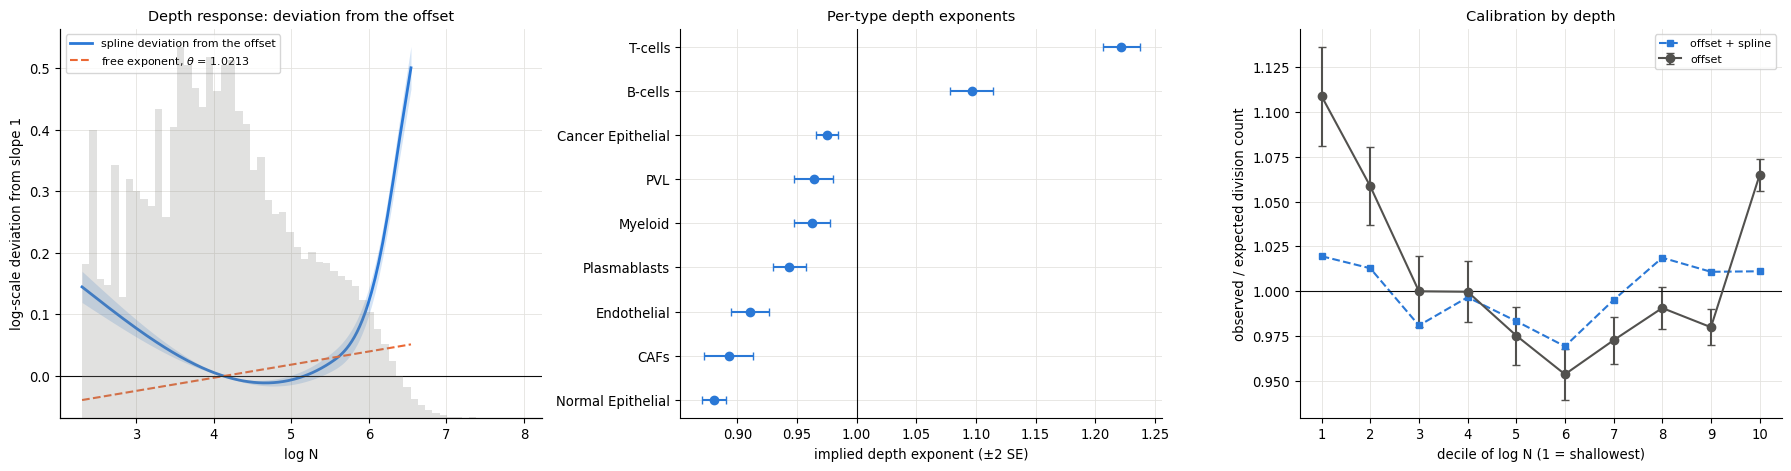

In [6]:
from tissue_dynamics.mixture.basis import _Spline
fo, fsp, fbt, ffr = tune[("offset", "const")], depth_fits["spline"], depth_fits["by_type"], tune[("free", "const")]
Nsp = _Spline(D["logN"], nbb.DEPTH_SPLINE_DF)          # the frozen basis load_design used
qN = np.quantile(D["logN"], np.linspace(0.005, 0.995, 200))
mN = D["logN"].mean()
v, Cv = nbb.estimate(fsp, "tN")
Bq = Nsp(qN) - Nsp(np.array([mN]))                      # deviation, pinned to 0 at mean log N
dev, dev_se = Bq @ v, np.sqrt(np.einsum("ij,jk,ik->i", Bq, Cv, Bq))
th_free = float(ffr["params"]["theta"])

vt, Ct = nbb.estimate(fbt, "tT")
slopes = pd.DataFrame({t: {"depth exponent": 1 + D["own"][ctype == t].mean(0) @ vt,
                           "se": float(np.sqrt(D["own"][ctype == t].mean(0) @ Ct @ D["own"][ctype == t].mean(0)))}
                       for t in TYPES}).T.sort_values("depth exponent")
cell_slope = 1 + D["own"] @ vt
print(f"per-cell depth exponent under the per-type model: 5-95% range "
      f"{np.percentile(cell_slope, 5):.3f}-{np.percentile(cell_slope, 95):.3f}")

dec = pd.qcut(D["logN"], 10, labels=False)
def oe(f):
    mu, a = f["mu"], f["alpha"]
    var = mu + (a if np.isscalar(a) else a) * mu ** 2
    o = np.bincount(dec, weights=y); e = np.bincount(dec, weights=mu); v_ = np.bincount(dec, weights=var)
    return o / e, np.sqrt(v_) / e
oe_off, oe_off_se = oe(fo); oe_sp, _ = oe(fsp)
dec_tab = pd.DataFrame({"median N": [np.median(df["N"].to_numpy()[dec == k]) for k in range(10)],
                        "O/E offset": oe_off, "se": oe_off_se, "O/E spline": oe_sp})
print(f"largest spline deviation from the offset over the central 99% of log N: "
      f"{np.max(np.abs(dev)):.3f} on the log scale ({100 * (np.exp(np.max(np.abs(dev))) - 1):.1f}%)")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
ax = axes[0]
ax.fill_between(qN, dev - 2 * dev_se, dev + 2 * dev_se, color=COL["real"], alpha=0.2, lw=0)
ax.plot(qN, dev, color=COL["real"], lw=2, label="spline deviation from the offset")
ax.plot(qN, (th_free - 1) * (qN - mN), "--", color=COL["decoy"], label=rf"free exponent, $\theta$ = {th_free:.4f}")
ax.axhline(0, color=INK, lw=0.8)
ax.set_xlabel("log N"); ax.set_ylabel("log-scale deviation from slope 1"); ax.legend(fontsize=8)
ax.set_title("Depth response: deviation from the offset")
ax2 = ax.twinx(); ax2.hist(D["logN"], bins=60, color=MUTED, alpha=0.25); ax2.set_yticks([]); ax2.grid(False)
ax = axes[1]
ax.errorbar(slopes["depth exponent"], np.arange(len(slopes)), xerr=2 * slopes["se"], fmt="o",
            color=COL["real"], capsize=3)
ax.axvline(1, color=INK, lw=0.8); ax.set_yticks(np.arange(len(slopes))); ax.set_yticklabels(slopes.index)
ax.set_xlabel("implied depth exponent (±2 SE)"); ax.set_title("Per-type depth exponents")
ax = axes[2]
ax.errorbar(np.arange(10) + 1, oe_off, yerr=2 * oe_off_se, fmt="o-", color=COL["base"], capsize=3, label="offset")
ax.plot(np.arange(10) + 1, oe_sp, "s--", color=COL["real"], ms=4, label="offset + spline")
ax.axhline(1, color=INK, lw=0.8); ax.set_xticks(np.arange(10) + 1)
ax.set_xlabel("decile of log N (1 = shallowest)"); ax.set_ylabel("observed / expected division count")
ax.set_title("Calibration by depth"); ax.legend(fontsize=8)
fig.tight_layout(); savefig(fig, "depth_offset_tests")
display(slopes.round(3)); dec_tab.round(4)

In [7]:
# Dispersion submodel: which cell types are over- or under-dispersed?
th_d = "offset"
fs, fc = tune[(th_d, "state")], tune[(th_d, "const")]
g = nbb.state_effects(fs, basis, "gamma")
g["exp(gamma)"] = np.exp(g["estimate"])
rc = nbb.rootogram(y, fc["mu"], fc["alpha"], groups=ctype)
rs = nbb.rootogram(y, fs["mu"], fs["alpha"], groups=ctype)
per = pd.DataFrame({t: {"cells": int((ctype == t).sum()),
                        "median alpha_i": float(np.median(fs["alpha"][ctype == t])),
                        "misfit, constant": nbb.misfit(*rc[t]), "misfit, state": nbb.misfit(*rs[t])}
                    for t in TYPES}).T
per["change %"] = 100 * (per["misfit, state"] / per["misfit, constant"] - 1)
print(f"constant alpha {fc['alpha']:.4f}; state alpha_i median {np.median(fs['alpha']):.4f}, "
      f"IQR {np.percentile(fs['alpha'], 25):.4f}-{np.percentile(fs['alpha'], 75):.4f}")
g[["exp(gamma)", "estimate", "se", "z"]].join(per).sort_values("exp(gamma)").round(3)

constant alpha 0.7449; state alpha_i median 0.7303, IQR 0.6737-0.7808


,exp(gamma),estimate,se,z,cells,median alpha_i,"misfit, constant","misfit, state",change %
CAFs,0.743,-0.297,0.040,-7.402,52506.0,0.563,63.839,37.255,-41.642
Normal Epithelial,0.810,-0.211,0.035,-6.009,53149.0,0.676,173.958,151.327,-13.010
Plasmablasts,0.892,-0.115,0.045,-2.557,42228.0,0.675,59.331,52.954,-10.749
B-cells,0.992,-0.008,0.034,-0.245,57825.0,0.701,111.064,102.151,-8.026
T-cells,1.052,0.051,0.022,2.343,89213.0,0.738,255.496,251.485,-1.570
PVL,1.065,0.063,0.045,1.399,40175.0,0.733,36.179,34.315,-5.152
Endothelial,1.072,0.070,0.031,2.269,47810.0,0.749,57.097,57.700,1.056
Myeloid,1.204,0.186,0.028,6.716,68186.0,0.795,84.396,92.121,9.153
Cancer Epithelial,1.299,0.261,0.022,11.906,110805.0,0.775,695.941,708.449,1.797


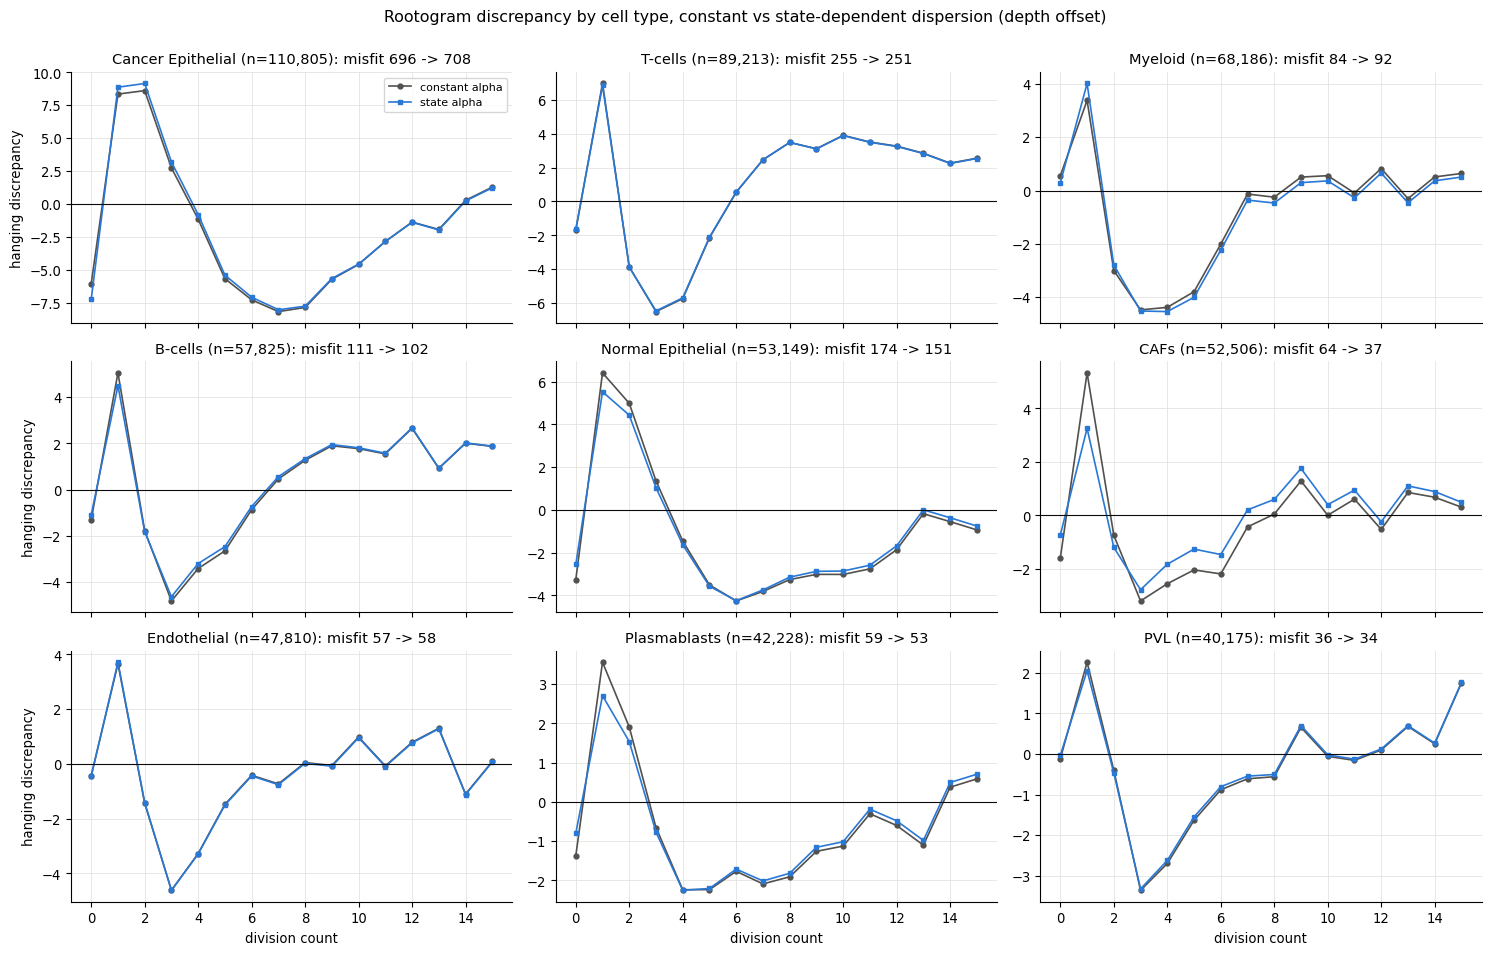

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(15, 9.5), sharex=True)
for ax, t in zip(axes.ravel(), sorted(TYPES, key=lambda t: -(ctype == t).sum())):
    for lab, R, c, m in (("constant alpha", rc, COL["base"], "o"), ("state alpha", rs, COL["real"], "s")):
        o, e = R[t]
        ax.plot(KS, (np.sqrt(o) - np.sqrt(e))[:16], m + "-", ms=3.5, lw=1.2, color=c, label=lab)
    ax.axhline(0, color=INK, lw=0.8)
    ax.set_title(f"{t} (n={(ctype == t).sum():,}): misfit {per.loc[t, 'misfit, constant']:.0f} "
                 f"-> {per.loc[t, 'misfit, state']:.0f}")
axes[0, 0].legend(fontsize=8)
for ax in axes[-1]: ax.set_xlabel("division count")
for ax in axes[:, 0]: ax.set_ylabel("hanging discrepancy")
fig.suptitle("Rootogram discrepancy by cell type, constant vs state-dependent dispersion (depth offset)", y=1.0)
fig.tight_layout(); savefig(fig, "tuning_dispersion_by_type")

### Reading §2

**On average, depth enters almost proportionally.** The free exponent is
$\hat\theta = 1.021$ (SE 0.004). Freeing it gains 13.5 log-likelihood units
(LR 27 on 1 df), and no own or neighbour effect moves by more than 0.63 SE
(correlation 0.9998 between the two sets of effects). Under the earlier weight
model the exponent was 1.0005; the 2% departure appeared with the final weight
model and changes none of the state effects.

**But not across the whole range, and not for every cell type.**
- **Spline.** A spline deviation from the offset gains 571 units (LR 1,142 on
  5 df) and cuts rootogram misfit by 30% (930 to 651). Under the offset,
  observed/expected is 1.11 in the shallowest decile (median N = 13), 0.95–1.0
  in the middle and 1.06 in the deepest (median N = 385). The spline flattens
  that to 0.97–1.02.
- **Per-type slopes.** They gain 749 units (LR 1,499 on 8 df). Implied exponents
  run from 0.88 (Normal Epithelial) to 1.22 (T-cells), but rootogram misfit
  improves by only 3%.

Neither departure is a reason to free depth. The shallow-cell excess looks like
an *additive* background (ambient or spilled transcripts, which matter most
where N is small), and the mixture's Stage C term models exactly that. The
deep-cell and per-type slopes are likely biology leaking into the technical
term, because cycling cells carry more RNA. A flexible depth term would absorb
division signal. **Decision (user, 2026-10-06): the offset stays.** Testing Stage C
for the shallow-cell excess is an open item.

**State-dependent dispersion helps the marginal fit, not calibration.**
- LR 283 on 8 df; rootogram misfit falls 7% (930 to 865).
- The gain sits mostly in CAFs (−42%), Normal Epithelial (−13%) and
  Plasmablasts (−11%). Myeloid (+9%) and Cancer Epithelial (+2%) get slightly
  worse.
- The PIT worsens (0.047 to 0.051), and residual Moran's I is unchanged (0.075).
- Over-dispersed types: Cancer Epithelial ($e^\gamma$ = 1.30) and Myeloid
  (1.20). Under-dispersed: CAFs (0.74) and Normal Epithelial (0.81).

Every specification keeps the same shape defect: an excess at counts 1–2 and a
deficit at 3–11, largest at 5–7. The mixture exists to fix that.

**Baseline for §3–5: offset, constant $\alpha$, no oxygen.** The reasoning and
the decision log are in the [specification decisions document](https://claude.ai/code/artifact/70c686de-ba2d-4b2d-8d17-f29b5e2c2077).

In [9]:
BASE = dict(theta="offset", dispersion="const")    # the decision above
base_fit = tune[(BASE["theta"], BASE["dispersion"])]
print("baseline:", BASE, "| no oxygen term |", f"loglik {base_fit['loglik']:,.1f} | "
      f"alpha {base_fit['alpha']:.4f} | {nbb.n_params(base_fit['params'])} parameters")

baseline: {'theta': 'offset', 'dispersion': 'const'} | no oxygen term | loglik -596,377.0 | alpha 0.7449 | 150 parameters


## 3. The oxygen field

**Status: dropped.** On the evidence below, $\psi\,u$ was removed from every
model on 2026-10-06 (`model.oxygen: false`). The baseline has no oxygen term,
and this section adds it back only to test it.

The field is a steady-state screened-diffusion solve over the rasterised
section (`tissue_dynamics.oxygen`):

$$\nabla^2 u = \kappa(x)\,u, \qquad -\nabla u\cdot\hat n = \beta\,\Phi(x)\,(1-u).$$

$\Phi$ marks the endothelial source cells. Consumption
$\kappa = (1/L_0^2)(n/n_0)$ rises with local density, so $L_0$ is the screening
length at reference density: roughly how far oxygen reaches from a vessel. $u$
is scale-free relative oxygenation in $[0,1]$, not pO₂.

**What changed.** The source is now the log1p Endothelial score of typed cells
($N \ge 10$). The top 2.6% after z-scoring are sources, at grid pitch 5 µm,
$L_0 = 100$ µm and $\beta = 1$. The old field came from the SpaNorm minor
table, whose endothelial columns tracked depth. It did not mark vessels: AUROC
0.515 for marker-identified endothelium. Every oxygen result in the old
notebook therefore needs redoing, including:
- the ~13× margin over the rotated decoy;
- the $L_0$ optimum at 100–200 µm;
- the HIF failure.

One deviation to keep in mind: the major-table Endothelial column includes
lymphatic endothelium, which carries no oxygenated blood. The old source
excluded it.

The plan:
1. Rebuild the field and check that it reproduces the table column.
2. Test that its source marks vessels.
3. Rerun the HIF-marker gate.
4. Test whether $u$ explains division beyond cell state, against three decoys,
   at every $L_0$ in the sweep.

In [10]:
cells = nbb.cached("all_cells", lambda: nbb.all_cells(cfg))
src_xy, src_score = nbb.oxygen_source(cells, cfg)
txy = df[["x", "y"]].to_numpy(float)
L0S = (50.0, 100.0, 200.0, 400.0, 800.0)

f100 = nbb.cached("field_L100", lambda: nbb.field_samples(txy, src_xy, src_score, 100.0, cfg,
                                                          keep_raster=True))
print(f"{len(cells):,} cells with PhiSpace scores, {cells['typed'].sum():,} typed; "
      f"{(src_score > 0).sum():,} sources ({100 * (src_score > 0).mean():.2f}% of typed cells)")
print(f"reproduces the table's oxygen column: max |difference| = "
      f"{np.nanmax(np.abs(f100['u'] - df['oxygen'].to_numpy())):.1e}")

# zoom window: the 2.5 mm square (500 px) where u varies most, among windows >= 95% tissue
R = f100["raster"]; blk, wb = 100, 5
best, WIN = -1.0, None
for a in range(R.shape[0] // blk - wb + 1):
    for b in range(R.shape[1] // blk - wb + 1):
        w = R[a * blk:(a + wb) * blk, b * blk:(b + wb) * blk]
        if np.isfinite(w).mean() >= 0.95 and np.nanstd(w) > best:
            best, WIN = float(np.nanstd(w)), ((a * blk, (a + wb) * blk), (b * blk, (b + wb) * blk))

fields = {}
for L0 in L0S:
    F = f100 if L0 == 100.0 else nbb.cached(f"field_L{int(L0)}", lambda L0=L0: nbb.field_samples(
        txy, src_xy, src_score, L0, cfg, keep_raster=True))
    fields[L0] = dict(F, window=F["raster"][WIN[0][0]:WIN[0][1], WIN[1][0]:WIN[1][1]])
xa, sa = nbb.oxygen_source(cells, cfg, consumers="all")
f_all = nbb.cached("field_L100_allconsumers", lambda: nbb.field_samples(txy, xa, sa, 100.0, cfg))

rows = []
for L0, F in fields.items():
    u, d = F["u"], F["diagnostics"]; ok = np.isfinite(u)
    rows.append({"L0": L0, "unknowns": d["n_unknowns"], "rel_residual": d["rel_residual"],
                 "mean u": np.nanmean(u), "sd u": np.nanstd(u),
                 "corr(u, log N)": np.corrcoef(u[ok], logN[ok])[0, 1],
                 "corr(u, log density)": np.corrcoef(u[ok], np.log(df["density"].to_numpy())[ok])[0, 1],
                 "solve min": F["minutes"]})
field_tab = pd.DataFrame(rows).set_index("L0")
ok = np.isfinite(f_all["u"]) & np.isfinite(f100["u"])
print(f"variant where shallow cells also consume oxygen: corr with production {np.corrcoef(f_all['u'][ok], f100['u'][ok])[0, 1]:.4f}, "
      f"mean u {np.nanmean(f_all['u']):.3f} vs {np.nanmean(f100['u']):.3f}")
field_tab

683,218 cells with PhiSpace scores, 564,004 typed; 14,665 sources (2.60% of typed cells)
reproduces the table's oxygen column: max |difference| = 1.1e-09


variant where shallow cells also consume oxygen: corr with production 0.9754, mean u 0.310 vs 0.333


,unknowns,rel_residual,mean u,sd u,"corr(u, log N)","corr(u, log density)",solve min
L0,,,,,,,
50.0,4501235,8.6586e-11,0.1312,0.1247,-0.0840,-0.2222,0.3118
100.0,4501235,9.5301e-11,0.3335,0.1671,-0.0966,-0.2700,0.3686
200.0,4501235,8.0096e-11,0.6314,0.1493,-0.0874,-0.2609,0.3683
400.0,4501235,7.1389e-11,0.8598,0.0900,-0.0601,-0.1818,0.3572
800.0,4501235,9.1375e-11,0.9576,0.0480,-0.0235,-0.0567,0.3951


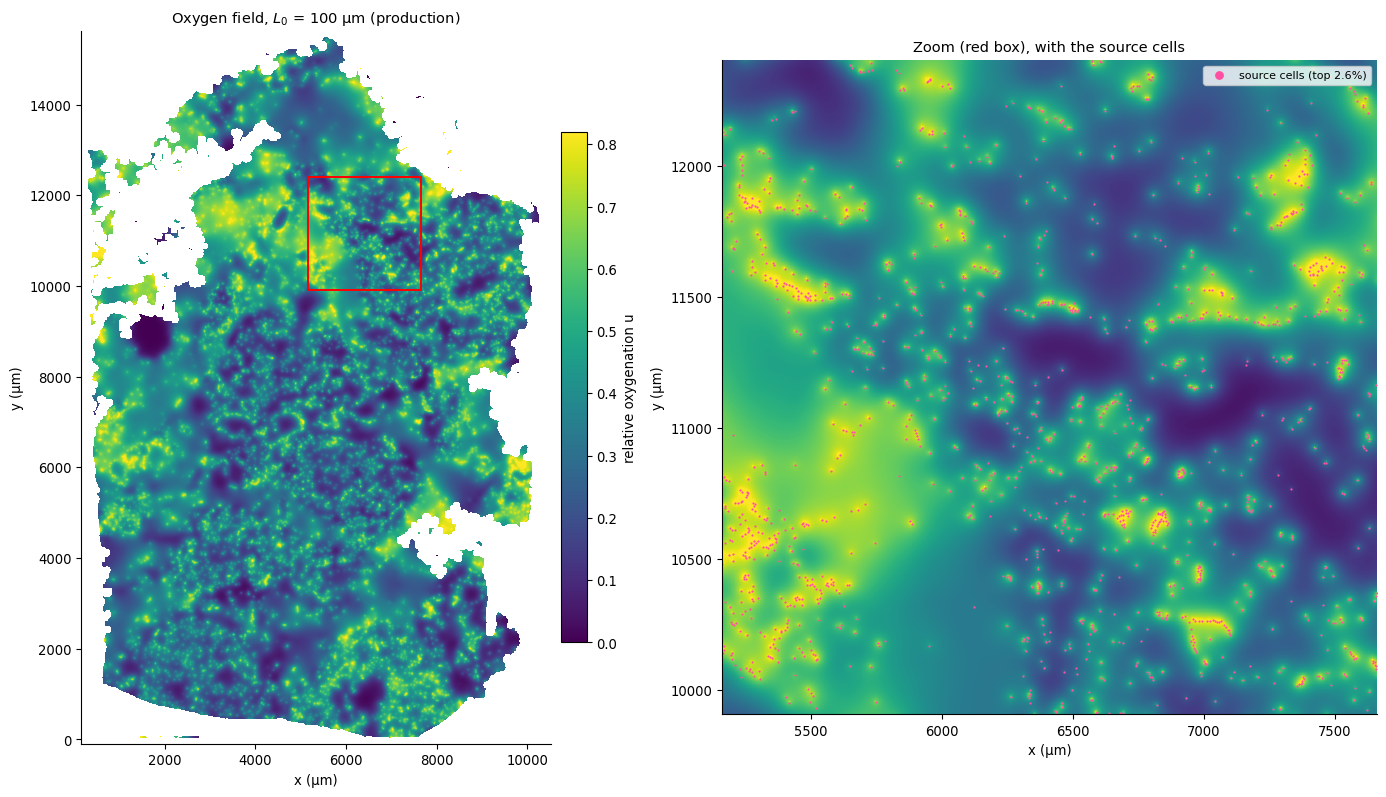

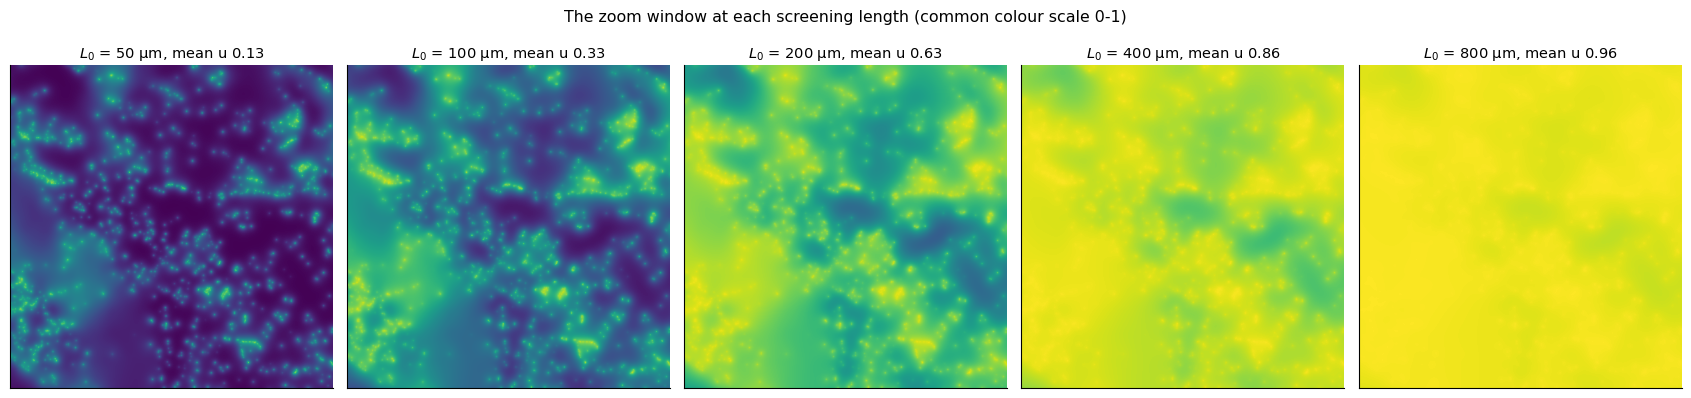

In [11]:
org, h = f100["origin"], f100["h"]
ext = [org[0], org[0] + R.shape[0] * h, org[1], org[1] + R.shape[1] * h]
(wi0, wi1), (wj0, wj1) = WIN
zext = [org[0] + wi0 * h, org[0] + wi1 * h, org[1] + wj0 * h, org[1] + wj1 * h]
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14, 8), gridspec_kw={"width_ratios": [0.78, 1]})
im = ax.imshow(R.T, origin="lower", extent=ext, cmap="viridis", vmin=0, vmax=np.nanpercentile(R, 99.5))
ax.add_patch(plt.Rectangle((zext[0], zext[2]), zext[1] - zext[0], zext[3] - zext[2], fill=False, ec="red", lw=1.4))
fig.colorbar(im, ax=ax, fraction=0.05, pad=0.02, label="relative oxygenation u")
ax.set_title(r"Oxygen field, $L_0$ = 100 µm (production)"); ax.grid(False)
ax = ax2
w = fields[100.0]["window"]
ax.imshow(w.T, origin="lower", extent=zext, cmap="viridis", vmin=0, vmax=np.nanpercentile(w, 99.5))
s = (src_score > 0) & (src_xy[:, 0] > zext[0]) & (src_xy[:, 0] < zext[1]) & (src_xy[:, 1] > zext[2]) & (src_xy[:, 1] < zext[3])
ax.scatter(src_xy[s, 0], src_xy[s, 1], s=2.5, c="#ff4fa3", lw=0, label="source cells (top 2.6%)")
ax.legend(loc="upper right", fontsize=8, markerscale=4); ax.set_title("Zoom (red box), with the source cells"); ax.grid(False)
for a in (fig.axes[0], ax2): a.set_xlabel("x (µm)"); a.set_ylabel("y (µm)")
fig.tight_layout(); savefig(fig, "oxygen_field_maps")

fig, axes = plt.subplots(1, len(L0S), figsize=(17, 3.9))
for ax, L0 in zip(axes, L0S):
    ax.imshow(fields[L0]["window"].T, origin="lower", extent=zext, cmap="viridis", vmin=0, vmax=1)
    ax.set_title(rf"$L_0$ = {L0:.0f} µm, mean u {field_tab.loc[L0, 'mean u']:.2f}")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle("The zoom window at each screening length (common colour scale 0-1)", y=1.02)
fig.tight_layout(); savefig(fig, "oxygen_field_by_L0")

### 3.1 Does the source mark vessels?

A field is only as good as its source. Marker-identified endothelium is used as
ground truth that does not depend on PhiSpace:
- **positives:** cells with ≥ 2 PECAM1 + CDH5 + CLDN5 counts, at least 3× their
  epithelial, T-cell, fibroblast and macrophage marker counts;
- **negatives:** cells with no endothelial counts and ≥ 3 other-lineage counts.

The AUROC asks how well a variable separates the two groups, scored at the
cells themselves. For $u$ that should be high, because endothelial cells sit at
the field's maxima. The decoys should score about 0.5.

In [12]:
gc_ = cells.set_index("cell_id").reindex(df["cell_id"])
endo_ct = gc_[[f"g_{m}" for m in nbb.ENDO_MARKERS]].sum(1).to_numpy()
other_ct = gc_[[f"g_{m}" for m in nbb.OTHER_MARKERS]].sum(1).to_numpy()
pos, neg = (endo_ct >= 2) & (endo_ct >= 3 * other_ct), (endo_ct == 0) & (other_ct >= 3)
print(f"marker endothelium {pos.sum():,} cells; marker-negative {neg.sum():,}")

def auroc(v):
    ok = np.isfinite(v) & (pos | neg)
    return roc_auc_score(pos[ok], v[ok])

auc = {"Endothelial PhiSpace score (the source)": auroc(gc_["phi_Endothelial"].to_numpy())}
for L0 in L0S:
    auc[f"u, L0 = {L0:.0f}"] = auroc(fields[L0]["u"])
for k in nbb.DECOYS:
    auc[f"decoy {k}, L0 = 100"] = auroc(f100["decoys"][k])
auc["u, L0 = 100, shallow cells also consume"] = auroc(f_all["u"])
auc_tab = pd.Series(auc, name="AUROC").to_frame()
auc_tab["(old SpaNorm field: 0.515)"] = ""
auc_tab.round(3)

marker endothelium 2,252 cells; marker-negative 27,973


,AUROC,(old SpaNorm field: 0.515)
Endothelial PhiSpace score (the source),0.985,
"u, L0 = 50",0.823,
"u, L0 = 100",0.788,
"u, L0 = 200",0.754,
"u, L0 = 400",0.735,
"u, L0 = 800",0.729,
"decoy rot180, L0 = 100",0.499,
"decoy flip_x, L0 = 100",0.507,
"decoy flip_y, L0 = 100",0.493,
"u, L0 = 100, shallow cells also consume",0.791,


### 3.2 The HIF-marker gate

The old §17 test, rerun on the new field: tile the section at 100 µm and ask
whether hypoxia-target expression falls where modelled oxygenation is high.
- Tiles need ≥ 20 cells.
- Rates are HIF-target transcripts per 1,000 total transcripts in the tile.
- The *partial* correlation ranks out tile depth, which inflated the old rates
  in shallow tissue.

The old core set had six genes. The Prime panel also carries a further ten
canonical HIF targets, used as an extended set. A clearly negative correlation
would license $u$ as a hypoxia proxy. A null is what the old notebook found,
and there it was blamed on the readout's sparsity.

In [13]:
genes_core = [g for g in nbb.HIF_CORE if f"g_{g}" in cells]
genes_ext = genes_core + [g for g in nbb.HIF_EXTENDED if f"g_{g}" in cells]
Tt = nbb.tiles(xc, yc, tile=100.0, min_cells=20)
tsum = lambda v: np.bincount(Tt["inv"], weights=v)[Tt["keep"]]
tot_t = tsum(gc_["total"].to_numpy(float))
logN_t = tsum(logN) / Tt["count"]

def partial_spearman(a, b, z):
    ra, rb, rz = (stats.rankdata(v) for v in (a, b, z))
    res = lambda v: v - np.polyval(np.polyfit(rz, v, 1), rz)
    return np.corrcoef(res(ra), res(rb))[0, 1]

rows = []
for lab, gl in (("core 6", genes_core), (f"extended {len(genes_ext)}", genes_ext)):
    rate = 1000 * tsum(gc_[[f"g_{g}" for g in gl]].sum(1).to_numpy(float)) / tot_t
    for L0 in L0S:
        ut = tsum(np.nan_to_num(fields[L0]["u"], nan=np.nanmean(fields[L0]["u"]))) / Tt["count"]
        rows.append({"genes": lab, "L0": L0, "Spearman(u, HIF rate)": stats.spearmanr(ut, rate).statistic,
                     "partial, depth ranked out": partial_spearman(ut, rate, logN_t)})
    rows.append({"genes": lab, "L0": "-", "Spearman(u, HIF rate)": stats.spearmanr(logN_t, rate).statistic,
                 "partial, depth ranked out": np.nan, "note": "row = Spearman(tile depth, HIF rate)"})
hif_tab = pd.DataFrame(rows)
print(f"{Tt['keep'].sum():,} tiles with >= 20 cells (median {np.median(Tt['count']):.0f} cells)")
per_gene = pd.DataFrame({g: {"cells detected %": 100 * (gc_[f"g_{g}"] > 0).mean(),
                             "tiles with zero %": 100 * (tsum(gc_[f"g_{g}"].to_numpy(float)) == 0).mean(),
                             "Spearman(u100, rate)": stats.spearmanr(
                                 tsum(np.nan_to_num(f100["u"])) / Tt["count"],
                                 tsum(gc_[f"g_{g}"].to_numpy(float)) / tot_t).statistic}
                         for g in genes_ext}).T
display(hif_tab.round(4)); per_gene.round(3)

7,624 tiles with >= 20 cells (median 64 cells)


,genes,L0,"Spearman(u, HIF rate)","partial, depth ranked out",note
0,core 6,50.0,0.2719,0.2336,NaN
1,core 6,100.0,0.2664,0.2244,NaN
2,core 6,200.0,0.2525,0.2104,NaN
3,core 6,400.0,0.2421,0.2011,NaN
4,core 6,800.0,0.2374,0.1971,NaN
5,core 6,-,-0.3669,NaN,"row = Spearman(tile depth, HIF rate)"
6,extended 16,50.0,0.2027,0.1507,NaN
7,extended 16,100.0,0.1974,0.1405,NaN
8,extended 16,200.0,0.1860,0.1291,NaN
9,extended 16,400.0,0.1782,0.1228,NaN


,cells detected %,tiles with zero %,"Spearman(u100, rate)"
CA9,0.242,84.942,-0.086
NDRG1,5.306,11.988,0.229
ADM,1.239,55.155,0.068
EGLN3,0.642,66.041,0.012
BNIP3,1.294,54.499,-0.149
ANGPTL4,0.716,67.550,0.085
VEGFA,7.177,10.113,0.072
SLC2A1,3.997,31.676,-0.194
PGK1,4.459,16.330,-0.013
LDHA,14.007,2.886,0.118


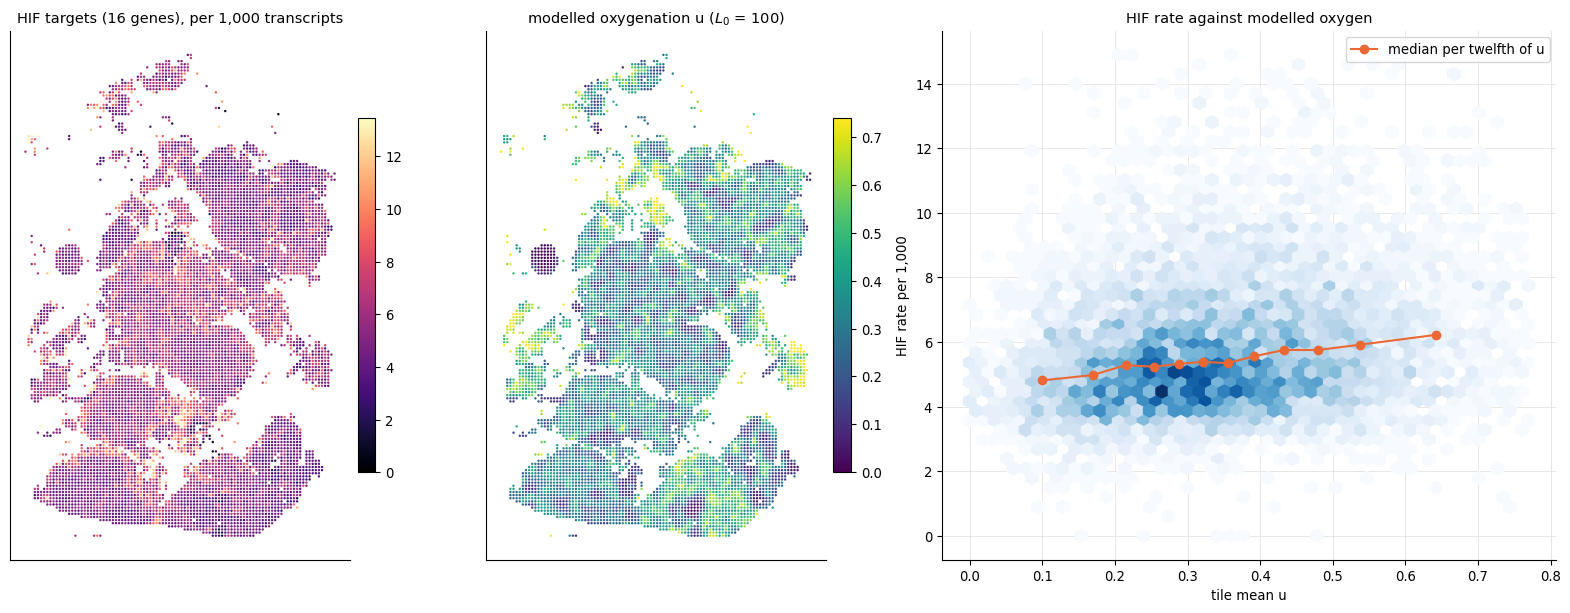

In [14]:
rate_ext = 1000 * tsum(gc_[[f"g_{g}" for g in genes_ext]].sum(1).to_numpy(float)) / tot_t
ut100 = tsum(np.nan_to_num(f100["u"])) / Tt["count"]
fig, axes = plt.subplots(1, 3, figsize=(16, 6.2), gridspec_kw={"width_ratios": [0.72, 0.72, 1.15]})
for ax, v, lab, cm in ((axes[0], rate_ext, f"HIF targets ({len(genes_ext)} genes), per 1,000 transcripts", "magma"),
                       (axes[1], ut100, r"modelled oxygenation u ($L_0$ = 100)", "viridis")):
    sc_ = ax.scatter(Tt["xy"][:, 0], Tt["xy"][:, 1], c=v, s=3, lw=0, cmap=cm,
                     vmin=0, vmax=np.percentile(v, 99))
    fig.colorbar(sc_, ax=ax, fraction=0.046, pad=0.02); ax.set_aspect("equal"); ax.set_title(lab)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
ax = axes[2]
ax.hexbin(ut100, rate_ext, gridsize=45, cmap="Blues", mincnt=1,
          extent=(0, np.percentile(ut100, 99.5), 0, np.percentile(rate_ext, 99.5)))
q = pd.qcut(ut100, 12, duplicates="drop")
med = pd.DataFrame({"u": ut100, "r": rate_ext}).groupby(q, observed=True).median()
ax.plot(med["u"], med["r"], "o-", color=COL["decoy"], label="median per twelfth of u")
ax.set_xlabel("tile mean u"); ax.set_ylabel("HIF rate per 1,000"); ax.legend(); ax.set_title("HIF rate against modelled oxygen")
fig.tight_layout(); savefig(fig, "oxygen_hif_gate")

### 3.3 Does $u$ explain division beyond cell state? Decoys and the $L_0$ sweep

The old §18 and §20, rerun with three decoys instead of one. Any smooth spatial
covariate soaks up some residual autocorrelation for free. So $u$ is judged
against the same raster:
- rotated 180° (point-reflected through the raster centre);
- mirrored in x;
- mirrored in y.

Each decoy has identical smoothness and marginal distribution, but is
misaligned with the tissue.

Every fit runs on one common cell set: cells inside the tissue mask under the
real field, all three decoys, and the all-consumers variant. That keeps every
likelihood and Moran's I comparable. The mask does not depend on $L_0$.

Each covariate is z-scored, so $\psi$ is the effect per SD of $u$ and is
comparable across $L_0$. The reference fit is the baseline on the common set, which has no oxygen term.
Each row of the table is one fit with one covariate added. Two measures compare real and
decoy:
- the drop in residual Moran's I, at the 100 µm tile scale;
- the likelihood gain.

In [15]:
valid = np.isfinite(f_all["u"])
for L0, F in fields.items():
    valid &= np.isfinite(F["u"])
    for k in nbb.DECOYS:
        valid &= np.isfinite(F["decoys"][k])
O = np.flatnonzero(valid)
T_O = nbb.tiles(xc[O], yc[O])
zs = lambda v: (v - v.mean()) / v.std()
print(f"common oxygen cell set: {len(O):,} cells ({100 * len(O) / n:.1f}%), {T_O['keep'].sum():,} tiles")

ox_base = nbb.cached("ox_base", lambda: nbb.fit(nbb.subset(D, O), init=base_fit["params"],
                                                say=print, **BASE, **PEN))
COVS = {(L0, kind): (fields[L0]["u"] if kind == "real" else fields[L0]["decoys"][kind])
        for L0 in L0S for kind in ("real",) + nbb.DECOYS}
COVS[(100.0, "all consumers")] = f_all["u"]
ox = {}
for (L0, kind), v in COVS.items():
    tag = f"ox_L{int(L0)}_{kind.replace(' ', '_')}"
    ox[(L0, kind)] = nbb.cached(tag, lambda v=v: nbb.fit(nbb.subset(D, O, oxygen=zs(v[O])),
                                                          init=ox_base["params"], say=print, **BASE, **PEN))

common oxygen cell set: 390,545 cells (69.5%), 7,100 tiles


In [16]:
yO = y[O]
I_base = nbb.tile_moran(nbb.pearson(yO, ox_base["mu"], ox_base["alpha"]), T_O, permutations=0)["I"]
rows = []
for (L0, kind), f in ox.items():
    v = COVS[(L0, kind)][O]
    psi, C = nbb.estimate(f, "psi")
    I = nbb.tile_moran(nbb.pearson(yO, f["mu"], f["alpha"]), T_O, permutations=0)["I"]
    rows.append({"L0": L0, "covariate": kind, "psi per SD": psi[0], "se": np.sqrt(C[0, 0]),
                 "z": psi[0] / np.sqrt(C[0, 0]), "LR vs no oxygen": 2 * (f["loglik"] - ox_base["loglik"]),
                 "resid Moran I": I, "Moran reduction": I_base - I,
                 "corr(cov, log N)": np.corrcoef(v, logN[O])[0, 1], "converged": f["info"]["converged"],
                 "attempts": f["info"].get("attempts", 1)})
ox_tab = pd.DataFrame(rows)
dec = ox_tab[ox_tab["covariate"].isin(nbb.DECOYS)].groupby("L0")
real = ox_tab[ox_tab["covariate"] == "real"].set_index("L0")
sweep = pd.DataFrame({
    "psi per SD": real["psi per SD"], "z": real["z"], "LR": real["LR vs no oxygen"],
    "decoy |z| max": dec["z"].apply(lambda s: s.abs().max()),
    "decoy LR max": dec["LR vs no oxygen"].max(),
    "Moran reduction": real["Moran reduction"],
    "decoy reduction mean": dec["Moran reduction"].mean(),
    "decoy reduction max": dec["Moran reduction"].max(),
    "corr(u, log N)": real["corr(cov, log N)"]})
sweep["LR margin over best decoy"] = sweep["LR"] / sweep["decoy LR max"].clip(lower=1e-9)
ox_tab.to_csv(OUT / "oxygen_fits.csv", index=False); sweep.to_csv(OUT / "oxygen_sweep.csv")
print(f"no-oxygen reference on the common set: residual Moran's I = {I_base:.4f}")
display(ox_tab[ox_tab["L0"] == 100.0].set_index("covariate").drop(columns="L0").round(4))
sweep.round(4)

no-oxygen reference on the common set: residual Moran's I = 0.0613


,psi per SD,se,z,LR vs no oxygen,resid Moran I,Moran reduction,"corr(cov, log N)",converged,attempts
covariate,,,,,,,,,
real,0.0141,0.0042,3.3212,11.8883,0.0612,0.0000,-0.0708,True,1
rot180,0.0065,0.0026,2.5175,6.3223,0.0614,-0.0001,0.0213,True,1
flip_x,-0.0015,0.0027,-0.5472,0.3002,0.0613,-0.0000,-0.0552,True,1
flip_y,0.0072,0.0025,2.8239,8.0384,0.0612,0.0000,0.0474,True,1
all consumers,0.0138,0.0039,3.5039,13.1309,0.0615,-0.0002,-0.0098,True,1


,psi per SD,z,LR,decoy |z| max,decoy LR max,Moran reduction,decoy reduction mean,decoy reduction max,"corr(u, log N)",LR margin over best decoy
L0,,,,,,,,,,
50.0,0.0167,3.6974,14.7841,1.7202,2.9903,0.0002,-0.0000,-0.0000,-0.0604,4.9440
100.0,0.0141,3.3212,11.8883,2.8239,8.0384,0.0000,-0.0000,0.0000,-0.0708,1.4789
200.0,0.0039,1.0493,1.2810,3.8447,14.8718,-0.0000,-0.0001,0.0002,-0.0602,0.0861
400.0,-0.0036,-1.1198,1.1458,4.0649,16.6076,0.0001,0.0000,0.0002,-0.0403,0.0690
800.0,-0.0060,-1.9213,3.5923,3.6774,13.4019,0.0002,0.0002,0.0005,-0.0215,0.2680


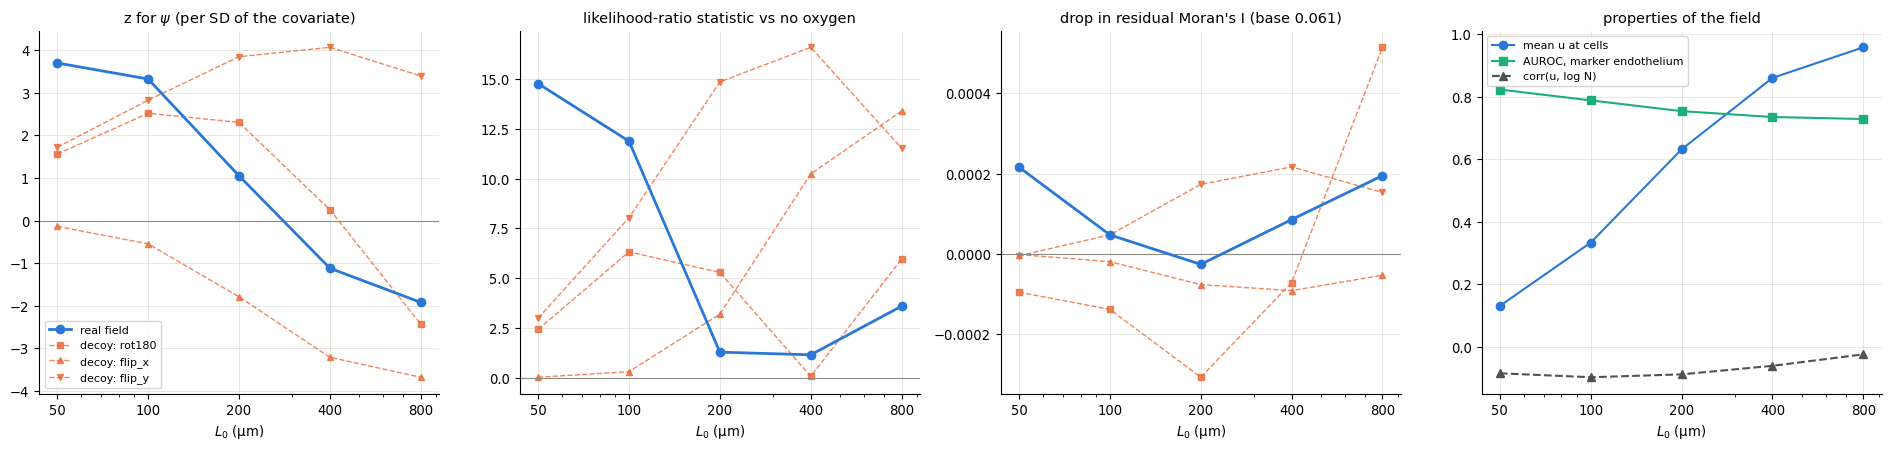

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4.6))
L = np.array(L0S)
dz = ox_tab[ox_tab["covariate"].isin(nbb.DECOYS)]
for ax, col, lab in ((axes[0], "z", r"z for $\psi$ (per SD of the covariate)"),
                     (axes[1], "LR vs no oxygen", "likelihood-ratio statistic vs no oxygen"),
                     (axes[2], "Moran reduction", f"drop in residual Moran's I (base {I_base:.3f})")):
    ax.plot(L, real[col], "o-", color=COL["real"], lw=2, label="real field", zorder=3)
    for k, mk in zip(nbb.DECOYS, ("s", "^", "v")):
        d = dz[dz["covariate"] == k].set_index("L0")[col]
        ax.plot(L, d, mk + "--", color=COL["decoy"], ms=5, lw=1, alpha=0.8, label=f"decoy: {k}")
    ax.axhline(0, color=MUTED, lw=0.8); ax.set_xscale("log"); ax.set_xticks(L); ax.set_xticklabels([f"{v:.0f}" for v in L])
    ax.set_xlabel(r"$L_0$ (µm)"); ax.set_title(lab)
axes[0].legend(fontsize=8)
ax = axes[3]
ax.plot(L, field_tab["mean u"], "o-", color=COL["real"], label="mean u at cells")
ax.plot(L, [auc_tab.loc[f"u, L0 = {v:.0f}", "AUROC"] for v in L], "s-", color=COL["alt"], label="AUROC, marker endothelium")
ax.plot(L, field_tab["corr(u, log N)"], "^--", color=COL["base"], label="corr(u, log N)")
ax.set_xscale("log"); ax.set_xticks(L); ax.set_xticklabels([f"{v:.0f}" for v in L])
ax.set_xlabel(r"$L_0$ (µm)"); ax.set_title("properties of the field"); ax.legend(fontsize=8)
fig.tight_layout(); savefig(fig, "oxygen_sweep")

### Reading §3

**The field marks vessels.** The source scores AUROC 0.985 against
marker-identified endothelium, and $u$ scores 0.79 at $L_0$ = 100 µm. The decoys
score 0.5, and corr$(u, \log N) = -0.10$. The old SpaNorm field scored 0.515 and
correlated +0.49 with depth. (The field does not depend on the weight model, so
these numbers are unchanged from the first run.)

**The HIF gate still fails.** Across 100 µm tiles, Spearman$(u,$ HIF rate$)$ is
+0.27 (6 genes) and +0.20 (16 genes), and stays positive with depth ranked out.
The composite is dominated by NDRG1, LDHA and PFKFB3, which all rise with $u$.
The specific markers (CA9, BNIP3, SLC2A1) fall with $u$, as they should, but
only weakly.

**$u$ adds almost nothing about division beyond cell state.**
- $|\psi| \le 0.017$ per SD at every $L_0$. Under the final weight model the
  short-range effect is now *positive* (more oxygen, more division): +0.017
  per SD at $L_0$ = 50 µm (z 3.7) and +0.014 at 100 µm (z 3.3). The first run,
  under the earlier weight model, gave −0.010.
- At the production $L_0$ = 100 µm, the real field gains LR 11.9, against 8.0
  for its y-mirror and 6.3 for its rotation: a margin of 1.5×.
- Only $L_0$ = 50 µm leads its decoys clearly (14.8 against at most 3.0).
- From 200 µm upward the decoys beat the real field (LR up to 14.9–16.6
  against 1.1–3.6).
- Residual Moran's I (0.061) falls by at most 0.0002.
- Letting shallow cells consume oxygen changes nothing ($\psi$ 0.0138 against
  0.0141).

A real field that beats its decoys only at the shortest screening length, by an
effect of under 2% per SD, is what short-range vessel proximity would look like
if it were mostly already in $\eta$ through the neighbours' Endothelial score.
The old notebook's 13× margin over the rotated decoy belonged to a field that
tracked depth.

**Decision (user, 2026-10-06): oxygen is dropped from every model.** The rerun
does not change it.

## 4. The annulus test: real neighbourhood effect, or segmentation spillover?

The 80 µm disc conflates two mechanisms:
- a **genuine neighbourhood effect**, where who surrounds a cell matters;
- **segmentation spillover**, where transcripts from a touching neighbour are
  assigned to this cell, so $\bar\phi$ partly echoes the cell's own
  mismeasured state.

Spillover is a contact artefact: it acts only between cells whose boundaries
touch. So the model is refit with $\bar\phi$ taken over successive rings, at
0–15, 15–30, 30–50, 50–80, 80–120 and 120–200 µm, and we watch the neighbour
effect move outward.

**The null.** Under pure spillover, a ring's coefficient is inherited from how
much its mean state still resembles the cell's own state:
$\hat c(r) = k\,\rho_\phi(r)$, where $\rho_\phi(r)$ is the PhiSpace correlogram
over every pair in the ring.

**Count matching.** A wide ring averages many more cells, so its $\bar\phi$ is
measured with less noise and suffers less regression dilution. That alone
inflates its coefficient. The count-matched control thins every ring at random
to the innermost ring's mean count, so all rings carry the same averaging noise.
This is the version to trust.

**Mechanics.**
- The neighbour pool is every typed cell, including the 2,107 outside the
  oxygen mask. Shallow cells are excluded, as in production.
- Each ring's mean replaces the neighbour block, as a single 8-coordinate
  block; the rest of the model is the baseline (offset, no oxygen). Every ring
  is centred, projected and whitened with **one common matrix**, the one that
  whitens the 80 µm disc mean. Per-ring whitening would rotate the coordinates
  from ring to ring, and the spillover test compares coordinate $d$ across
  rings.
- All rings are fit on one cell set: cells with at least one typed neighbour
  in every ring.
- Effects are reported per SD of the ring mean, per cell type $k$:
  $\beta_k = (Qc)_k \cdot \mathrm{sd}(\bar\phi_k)$.
- The spillover χ² runs on the eight projected coordinates. Unlike the nine
  cell-type effects, which sum to zero, these are not linearly dependent.

In [18]:
pool = cells.loc[cells["typed"]].reset_index(drop=True)
pxy = pool[["x", "y"]].to_numpy(float)
P = pool[[f"phi_{t}" for t in TYPES]].to_numpy(float)
focal = pd.Series(np.arange(len(pool)), index=pool["cell_id"]).reindex(df["cell_id"]).to_numpy()
# one projection for every ring: sum-to-zero, then the whitening of the 80 um disc mean
disc_all = df[[f"nbr_phi_{j:02d}" for j in range(len(TYPES))]].to_numpy(float)
_, Q_RING = nbb.project_block(disc_all, basis)
ring_proj = lambda Pb: (Pb - Pb.mean(0)) @ Q_RING
Pc = P - P.mean(0); Pq = Pc @ Q_RING
Zrho = np.column_stack([Pc / Pc.std(0), Pq / Pq.std(0)])      # 9 type scores, then 8 projected coords
cnt0 = nbb.ring_counts(pxy, focal, nbb.RINGS[0][1])
K_MATCH = int(round(cnt0.mean()))
ann = nbb.cached("annulus_rings_whitened", lambda: nbb.ring_means(pxy, P, focal, Zrho,
                                                                  max_neighbors=K_MATCH))
A = np.flatnonzero((ann["count"] > 0).all(0))
ring_lab = [f"{a:.0f}-{b:.0f}" for a, b in nbb.RINGS]
ring_tab = pd.DataFrame({"ring (µm)": ring_lab,
                         "mean neighbours": ann["count"].mean(1),
                         "count-matched": ann["count_matched"].mean(1),
                         "no neighbour %": 100 * (ann["count"] == 0).mean(1),
                         "pairs": ann["n_pairs"],
                         "rho (mean over types)": ann["rho"][:, :len(TYPES)].mean(1)}).set_index("ring (µm)")
print(f"count matching thins every ring to <= {K_MATCH} neighbours (the 0-15 µm mean is {cnt0.mean():.2f})")
print(f"annulus cell set: {len(A):,} cells ({100 * len(A) / n:.1f}%) with a typed neighbour in every ring")
ring_tab.round(3)

count matching thins every ring to <= 6 neighbours (the 0-15 µm mean is 6.31)
annulus cell set: 539,359 cells (96.0%) with a typed neighbour in every ring


,mean neighbours,count-matched,no neighbour %,pairs,rho (mean over types)
ring (µm),,,,,
0-15,6.312,4.590,3.484,3.5465e+06,0.256
15-30,18.665,5.727,0.969,1.0488e+07,0.191
30-50,42.175,5.893,0.272,2.3698e+07,0.157
50-80,98.498,5.976,0.033,5.5346e+07,0.131
80-120,193.199,5.996,0.009,1.0856e+08,0.106
120-200,583.917,6.000,0.001,3.2810e+08,0.078


In [19]:
ring_bar = {}
for r, lab in enumerate(ring_lab):
    for kind, S, Cn in (("naive", ann["sum"], ann["count"]), ("matched", ann["sum_matched"], ann["count_matched"])):
        ring_bar[(kind, lab)] = S[r][A] / Cn[r][A][:, None]
prod_bar = disc_all[A]                    # the 80 um disc mean, the annulus set's reference
DA = nbb.subset(D, A)                     # the production design (contact/regional split) on that set
ann_fit = {"none": nbb.cached("ann_nonbr", lambda: nbb.fit(nbb.subset(D, A, nbr=np.zeros((len(A), 8))),
                                                           init=base_fit["params"], say=print, **BASE, **PEN)),
           "disc 0-80": nbb.cached("ann_disc80", lambda: nbb.fit(nbb.subset(D, A, nbr=ring_proj(prod_bar)),
                                                                 init=base_fit["params"], say=print, **BASE, **PEN))}
for (kind, lab), Pb in ring_bar.items():
    ann_fit[(kind, lab)] = nbb.cached(f"ann_{kind}_{lab}", lambda Pb=Pb: nbb.fit(
        nbb.subset(D, A, nbr=ring_proj(Pb)), init=base_fit["params"], say=print, **BASE, **PEN))

In [20]:
def ring_effects(f, Pb):
    proj = ring_proj(Pb); sdp = proj.std(0); sdt = Pb.std(0)
    vt, Ct = nbb.estimate(f, "c", Q_RING)
    vp, Cp = nbb.estimate(f, "c")
    U, V = f["params"]["U"], f["params"]["V"]
    sig = np.linalg.svd(U @ V.T * sdp[None, :], compute_uv=False)
    return dict(beta=vt * sdt, beta_se=np.sqrt(np.diag(Ct)) * sdt,
                cproj=vp * sdp, cproj_se=np.sqrt(np.diag(Cp)) * sdp, sigma1_B=sig[0], sigma2_B=sig[1])

ll0 = ann_fit["none"]["loglik"]
summ, coef_rows, per_type = [], [], {}
for kind in ("naive", "matched"):
    for r, lab in enumerate(ring_lab):
        f = ann_fit[(kind, lab)]; e = ring_effects(f, ring_bar[(kind, lab)])
        summ.append({"version": kind, "ring": lab, "mean |beta|": np.abs(e["beta"]).mean(),
                     "||beta||": np.linalg.norm(e["beta"]), "sigma1(B) per SD": e["sigma1_B"],
                     "neighbour-block LR": 2 * (f["loglik"] - ll0),
                     "rho": ann["rho"][r, :len(TYPES)].mean(), "converged": f["info"]["converged"]})
        per_type[(kind, lab)] = pd.Series(e["beta"], index=TYPES)
        for d in range(len(e["cproj"])):
            coef_rows.append({"version": kind, "r_inner": nbb.RINGS[r][0], "r_outer": nbb.RINGS[r][1],
                              "dim": f"q{d + 1}", "c": e["cproj"][d], "se": e["cproj_se"][d],
                              "rho_pair": ann["rho"][r, len(TYPES) + d]})
ed = ring_effects(ann_fit["disc 0-80"], prod_bar)
summ.append({"version": "reference", "ring": "disc 0-80", "mean |beta|": np.abs(ed["beta"]).mean(),
             "||beta||": np.linalg.norm(ed["beta"]), "sigma1(B) per SD": ed["sigma1_B"],
             "neighbour-block LR": 2 * (ann_fit["disc 0-80"]["loglik"] - ll0), "rho": np.nan,
             "converged": ann_fit["disc 0-80"]["info"]["converged"]})
ann_tab = pd.DataFrame(summ)
for kind in ("naive", "matched"):
    m = ann_tab["version"] == kind
    b0, r0 = ann_tab.loc[m, "mean |beta|"].iloc[0], ann_tab.loc[m, "rho"].iloc[0]
    ann_tab.loc[m, "beta(r)/beta(0)"] = ann_tab.loc[m, "mean |beta|"] / b0
    ann_tab.loc[m, "rho(r)/rho(0)"] = ann_tab.loc[m, "rho"] / r0
ann_tab["ratio"] = ann_tab["beta(r)/beta(0)"] / ann_tab["rho(r)/rho(0)"]
coef = pd.DataFrame(coef_rows)
chi = {kind: spillover_chi2(coef[coef["version"] == kind]) for kind in ("naive", "matched")}
for kind, res in chi.items():
    print(f"spillover null c_d(r) = k_d rho_d(r), {kind}: chi2 = {res['chi2']:.0f} on {res['df']} df")
ann_tab.to_csv(OUT / "annulus.csv", index=False)
ann_tab.round(4)

spillover null c_d(r) = k_d rho_d(r), naive: chi2 = 1226 on 40 df
spillover null c_d(r) = k_d rho_d(r), matched: chi2 = 875 on 40 df


,version,ring,mean |beta|,||beta||,sigma1(B) per SD,neighbour-block LR,rho,converged,beta(r)/beta(0),rho(r)/rho(0),ratio
0,naive,0-15,0.0367,0.1556,0.3223,5172.5594,0.2563,True,1.0000,1.0000,1.0000
1,naive,15-30,0.0311,0.1228,0.2315,4564.6106,0.1913,True,0.8464,0.7465,1.1338
2,naive,30-50,0.0273,0.1075,0.1751,3809.5461,0.1573,True,0.7441,0.6137,1.2126
3,naive,50-80,0.0261,0.1056,0.1273,3312.9559,0.1306,True,0.7113,0.5098,1.3953
4,naive,80-120,0.0262,0.1096,0.0932,2821.7769,0.1059,True,0.7128,0.4132,1.7251
5,naive,120-200,0.0317,0.1293,0.0648,2555.9267,0.0776,True,0.8639,0.3027,2.8542
6,matched,0-15,0.0357,0.1507,0.3218,4987.0792,0.2563,True,1.0000,1.0000,1.0000
7,matched,15-30,0.0249,0.1016,0.2327,3557.0696,0.1913,True,0.6974,0.7465,0.9341
8,matched,30-50,0.0181,0.0778,0.1827,2471.5050,0.1573,True,0.5066,0.6137,0.8256
9,matched,50-80,0.0157,0.0648,0.1432,1818.7981,0.1306,True,0.4412,0.5098,0.8656


In [21]:
# Per-type neighbour effects (per SD of the ring mean), count-matched rings, beside the 80 um disc
bt = pd.DataFrame({lab: per_type[("matched", lab)] for lab in ring_lab})
bt["disc 0-80"] = pd.Series(ed["beta"], index=TYPES)
bt["120-200 / 0-15"] = bt["120-200"] / bt["0-15"]
bt.round(3)

,0-15,15-30,30-50,50-80,80-120,120-200,disc 0-80,120-200 / 0-15
Endothelial,-0.047,-0.035,-0.029,-0.023,-0.022,-0.020,-0.052,0.430
CAFs,-0.023,-0.016,-0.009,-0.007,-0.005,-0.006,-0.012,0.275
PVL,-0.015,-0.007,-0.007,-0.006,-0.005,-0.004,0.008,0.259
B-cells,-0.006,-0.007,-0.008,-0.006,-0.008,-0.011,-0.005,1.805
T-cells,0.032,0.015,0.008,0.009,0.011,0.007,0.027,0.228
Myeloid,-0.035,-0.027,-0.010,-0.007,-0.004,0.001,-0.015,-0.041
Normal Epithelial,-0.013,-0.007,-0.006,-0.012,-0.011,-0.007,-0.035,0.549
Plasmablasts,0.022,0.026,0.018,0.017,0.014,0.014,0.035,0.650
Cancer Epithelial,0.130,0.084,0.067,0.054,0.049,0.035,0.097,0.267


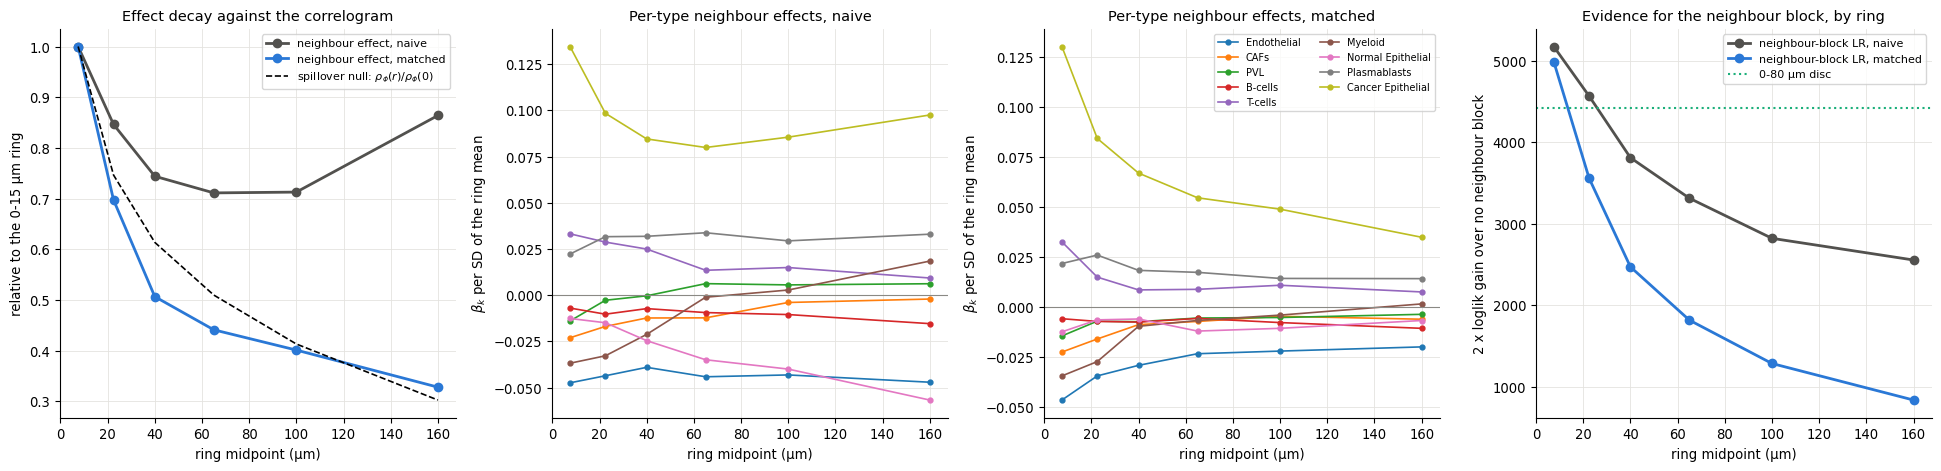

In [22]:
fig, axes = plt.subplots(1, 4, figsize=(19.5, 4.8))
mid = np.array([(a + b) / 2 for a, b in nbb.RINGS])
ax = axes[0]
for kind, c in (("naive", COL["base"]), ("matched", COL["real"])):
    t = ann_tab[ann_tab["version"] == kind]
    ax.plot(mid, t["beta(r)/beta(0)"], "o-", color=c, lw=2, label=f"neighbour effect, {kind}")
ax.plot(mid, ann_tab[ann_tab["version"] == "matched"]["rho(r)/rho(0)"], "k--", lw=1.2,
        label=r"spillover null: $\rho_\phi(r)/\rho_\phi(0)$")
ax.set_xlabel("ring midpoint (µm)"); ax.set_ylabel("relative to the 0-15 µm ring"); ax.legend(fontsize=8)
ax.set_title("Effect decay against the correlogram")
for ax, kind in ((axes[1], "naive"), (axes[2], "matched")):
    M = pd.DataFrame({lab: per_type[(kind, lab)] for lab in ring_lab})
    for t in TYPES:
        ax.plot(mid, M.loc[t], "o-", ms=3.5, lw=1.2, label=t)
    ax.axhline(0, color=MUTED, lw=0.8); ax.set_xlabel("ring midpoint (µm)")
    ax.set_ylabel(r"$\beta_k$ per SD of the ring mean"); ax.set_title(f"Per-type neighbour effects, {kind}")
axes[2].legend(fontsize=7, ncol=2)
ax = axes[3]
for kind, c in (("naive", COL["base"]), ("matched", COL["real"])):
    t = ann_tab[ann_tab["version"] == kind]
    ax.plot(mid, t["neighbour-block LR"], "o-", color=c, lw=2, label=f"neighbour-block LR, {kind}")
ax.axhline(ann_tab.loc[ann_tab["version"] == "reference", "neighbour-block LR"].iloc[0], color=COL["alt"],
           ls=":", lw=1.5, label="0-80 µm disc")
ax.set_xlabel("ring midpoint (µm)"); ax.set_ylabel("2 x loglik gain over no neighbour block")
ax.set_title("Evidence for the neighbour block, by ring"); ax.legend(fontsize=8)
fig.tight_layout(); savefig(fig, "annulus")

### Reading §4

**Naive rings repeat the old dilution artefact.** The effect dips to 0.71× by
50–120 µm, then climbs back to 0.86× at 120–200 µm, where each ring mean averages
584 cells instead of 6. Its ratio to the correlogram reaches 2.9.

**With count matching, the effect decays in step with the correlogram.** Each
ring holds at most 6 neighbours.

| ring (µm) | 0–15 | 15–30 | 30–50 | 50–80 | 80–120 | 120–200 |
|---|---|---|---|---|---|---|
| neighbour effect, relative | 1 | 0.70 | 0.51 | 0.44 | 0.40 | 0.33 |
| $\rho_\phi$, relative | 1 | 0.75 | 0.61 | 0.51 | 0.41 | 0.30 |
| ratio | 1 | 0.93 | 0.83 | 0.87 | 0.97 | 1.08 |

This is the first run's profile to two decimals. The old notebook's ratios of
1.1–1.4, read as an effect with its own range, do not replicate. The χ² for
exact proportionality is 875 on 40 df (256 in the first run). It is approximate
(model-based SEs, every ring fit on the same cells), and the shape is the
robust part.

**What this says.** Spillover cannot act at 120–200 µm, yet a third of the
contact effect remains there (neighbour-block LR 840). The far effect is
regional composition, falling off as fast as composition decorrelates.
Meanwhile, the 0–15 µm ring alone (at most 6 cells) carries more evidence than
the whole 80 µm disc (LR 4,987 against 4,415).

**By cell type.** Cancer Epithelial carries the largest effect at every ring
(0.130 per SD at contact, 0.035 at 120–200 µm). The Endothelial effect is
negative throughout (−0.047 to −0.020). The T-cell effect is a contact effect
(0.032 to 0.007). Plasmablasts are flattest (0.022 to 0.014).

## 5. Neighbourhood structure: how should $\bar\phi$ weight its neighbours?

§4 found that the contact ring carries the most information. The 80 µm disc
weights every neighbour equally, so it dilutes the closest cells with about
95 more distant ones. Here several alternatives compete as *predictors*, all
on the annulus cell set with the baseline model.

- **Uniform disc 0–80 µm.** The neighbour block until 2026-10-07, and the
  reference every model is scored against.
- **Split, two blocks:** contact (0–15 µm) and regional (15–80 µm) means,
  production since 2026-10-07. Each
  gets its own main effect $c$ and its own rows of $V$, so the bilinear term
  reads $(\phi^\top U)(\bar\phi_\text{contact}^\top V_1 + \bar\phi_\text{regional}^\top V_2)$.
  This doubles the neighbour block (+32 parameters at rank 3).
- **Split, three blocks:** adds a far block (80–200 µm), testing whether
  anything beyond 80 µm helps.
- **Six rings:** every annulus as its own block. This is the nonparametric
  distance profile and the upper bound on what any weighting could achieve
  (+160 parameters).
- **Exponential decay:**
  $\bar\phi_i = \sum_j w_{ij}\phi_j / \sum_j w_{ij}$ with
  $w_{ij} = e^{-d_{ij}/\ell}$ out to 200 µm, for
  $\ell \in \{5, 10, 20, 40, 80, 160\}$ µm. This has the same parameter count
  as the disc. $\ell$ is profiled over the grid: the best $\ell$ is the kernel
  the data prefer.

Each neighbourhood block is centred, projected and whitened by its own
covariance, as the production basis treats the contact and regional blocks.

In-sample likelihood rewards the bigger blocks automatically, and spatial
autocorrelation makes AIC and BIC too lenient. The arbiter is therefore
**spatial 5-fold cross-validation**:
- folds are the stored map from the mixture's CV (contiguous blocks;
  `outputs/division_classifier/folds.parquet`, written on Spartan);
- the criterion is the held-out NB log-likelihood.

**A caution on contact terms.** Segmentation spillover acts exactly at contact,
so a model that up-weights touching cells can partly be fitting the artefact,
not biology. The split model makes the contact block explicit, so its effects
can be compared with the own-state effects.

In [23]:
def ring_mean(rs):
    S = sum(ann["sum"][r] for r in rs)[A]; Cn = sum(ann["count"][r] for r in rs)[A]
    return S / Cn[:, None]

print(f"0-80 µm disc rebuilt from the rings vs the table's 80 µm disc mean: max |difference| "
      f"{np.abs(ring_mean([0, 1, 2, 3]) - prod_bar).max():.1e}")
BLOCKS = {"contact": ring_mean([0]), "regional": ring_mean([1, 2, 3]), "far": ring_mean([4, 5])}
ELLS = (5.0, 10.0, 20.0, 40.0, 80.0, 160.0)
kern = nbb.cached("kernel_means", lambda: nbb.kernel_means(pxy, P, focal, ELLS))
K_BAR = {ell: (kern["sum"][e] / kern["W"][e][:, None])[A] for e, ell in enumerate(ELLS)}
neff = {ell: float(np.median((kern["W"][e] ** 2 / kern["W2"][e])[A])) for e, ell in enumerate(ELLS)}

prod_split = np.hstack([df[[f"{pre}{j:02d}" for j in range(len(TYPES))]].to_numpy(float)[A]
                        for pre in ("nbrc_phi_", "nbrr_phi_")])
print(f"contact + regional rebuilt from the rings vs the production split columns: max |difference| "
      f"{np.abs(np.hstack([BLOCKS['contact'], BLOCKS['regional']]) - prod_split).max():.1e}")
DISC, SPLIT = "disc 0-80", "split: contact + regional"
NBR, NBRQ = {}, {}
for name, blocks in ((DISC, [prod_bar]), (SPLIT, [BLOCKS["contact"], BLOCKS["regional"]]),
                     ("split: contact + regional + far", [BLOCKS["contact"], BLOCKS["regional"], BLOCKS["far"]]),
                     ("six rings", [ring_mean([r]) for r in range(6)])):
    NBR[name], NBRQ[name] = nbb.stack_nbr(blocks, basis, return_q=True)
for ell in ELLS:
    NBR[f"exp, ell = {ell:.0f}"], NBRQ[f"exp, ell = {ell:.0f}"] = nbb.stack_nbr([K_BAR[ell]], basis, return_q=True)
TAG = {k: k.replace("split: ", "split_").replace(" + ", "_").replace(", ell = ", "_l").replace(" ", "_")
       for k in NBR}
TAG[DISC] = "disc"
nbr_fit = {"none": ann_fit["none"]}
for name, X in NBR.items():
    nbr_fit[name] = nbb.cached(f"nbr_{TAG[name]}", lambda X=X: nbb.fit(
        nbb.subset(D, A, nbr=X), init=base_fit["params"], say=print, **BASE, **PEN))

0-80 µm disc rebuilt from the rings vs the table's 80 µm disc mean: max |difference| 2.3e-15


contact + regional rebuilt from the rings vs the production split columns: max |difference| 2.6e-15


In [24]:
T_A = nbb.tiles(xc[A], yc[A]); yA = y[A]
ll_disc, ll_none = nbr_fit[DISC]["loglik"], nbr_fit["none"]["loglik"]
k_disc = nbb.n_params(nbr_fit[DISC]["params"])
rows = []
for name, f in nbr_fit.items():
    k = nbb.n_params(f["params"])
    rows.append({"model": name, "nbr width": f["params"]["c"].size, "k": k, "loglik": f["loglik"],
                 "gain vs disc": f["loglik"] - ll_disc, "dAIC vs disc": 2 * (k - k_disc) - 2 * (f["loglik"] - ll_disc),
                 "dBIC vs disc": (k - k_disc) * np.log(len(A)) - 2 * (f["loglik"] - ll_disc),
                 "neighbour LR": 2 * (f["loglik"] - ll_none),
                 "resid Moran I": nbb.tile_moran(nbb.pearson(yA, f["mu"], f["alpha"]), T_A, permutations=0)["I"],
                 "median n_eff": next((neff[e] for e in ELLS if name == f"exp, ell = {e:.0f}"), np.nan),
                 "converged": f["info"]["converged"]})
nbr_tab = pd.DataFrame(rows).set_index("model")
nbr_tab.to_csv(OUT / "neighbourhood_models.csv")
exp_names = [f"exp, ell = {e:.0f}" for e in ELLS]
BEST_EXP = max(exp_names, key=lambda m: nbr_tab.loc[m, "loglik"])
print(f"best exponential kernel in sample: {BEST_EXP} (median {nbr_tab.loc[BEST_EXP, 'median n_eff']:.1f} "
      f"effective neighbours, against ~{ann['count'][:4].sum(0)[A].mean():.0f} in the disc)")
nbr_tab.round(2)

best exponential kernel in sample: exp, ell = 10 (median 23.3 effective neighbours, against ~171 in the disc)


,nbr width,k,loglik,gain vs disc,dAIC vs disc,dBIC vs disc,neighbour LR,resid Moran I,median n_eff,converged
model,,,,,,,,,,
none,8,118,-585760.33,-2207.38,4414.75,4414.75,0.00,0.13,NaN,True
disc 0-80,8,118,-583552.95,0.00,0.00,0.00,4414.75,0.09,NaN,True
split: contact + regional,16,150,-582461.98,1090.97,-2117.94,-1759.60,6596.70,0.08,NaN,True
split: contact + regional + far,24,182,-582172.42,1380.53,-2633.06,-1916.38,7175.82,0.08,NaN,True
six rings,48,278,-582023.95,1529.00,-2738.01,-946.31,7472.76,0.08,NaN,True
"exp, ell = 5",8,118,-582761.54,791.42,-1582.83,-1582.83,5997.59,0.10,8.17,True
"exp, ell = 10",8,118,-582629.89,923.06,-1846.12,-1846.12,6260.87,0.09,23.35,True
"exp, ell = 20",8,118,-582910.64,642.31,-1284.63,-1284.63,5699.38,0.08,79.40,True
"exp, ell = 40",8,118,-583403.61,149.34,-298.68,-298.68,4713.43,0.08,273.62,True


In [25]:
# What each neighbourhood contributes, per SD of its mean, in cell-type coordinates
def type_effects(f, Qs, blocks, j):
    # per-type effects of stacked block j (8 columns each), per SD of that block's ring mean
    Qn = Qs[j]; w = Qn.shape[1]
    v, C = nbb.estimate(f, "c")
    vj, Cj = v[j * w:(j + 1) * w], C[j * w:(j + 1) * w, j * w:(j + 1) * w]
    sd = blocks[j].std(0)
    return pd.DataFrame({"beta": (Qn @ vj) * sd, "se": np.sqrt(np.diag(Qn @ Cj @ Qn.T)) * sd}, index=TYPES)

own_sd = df[[f"phi_{j:02d}" for j in range(len(TYPES))]].to_numpy()[A].std(0)
own_eff = nbb.state_effects(nbr_fit[SPLIT], basis, "a")["estimate"] * own_sd
sp2 = [BLOCKS["contact"], BLOCKS["regional"]]
eff_c = type_effects(nbr_fit[SPLIT], NBRQ[SPLIT], sp2, 0)
eff_r = type_effects(nbr_fit[SPLIT], NBRQ[SPLIT], sp2, 1)
split_tab = pd.DataFrame({"own (per SD)": own_eff, "contact": eff_c["beta"], "contact se": eff_c["se"],
                          "regional": eff_r["beta"], "regional se": eff_r["se"]})
print(f"corr(contact effects, own effects) = {np.corrcoef(split_tab['contact'], split_tab['own (per SD)'])[0, 1]:+.3f}; "
      f"corr(regional, own) = {np.corrcoef(split_tab['regional'], split_tab['own (per SD)'])[0, 1]:+.3f}; "
      f"corr(contact, regional) = {np.corrcoef(split_tab['contact'], split_tab['regional'])[0, 1]:+.3f}")

r6 = [ring_mean([r]) for r in range(6)]
prof = pd.DataFrame({lab: type_effects(nbr_fit["six rings"], NBRQ["six rings"], r6, r)["beta"]
                     for r, lab in enumerate(ring_lab)})
ref = prof.iloc[:, 0].to_numpy()
ring_prof = pd.DataFrame({"||beta|| (per SD)": np.linalg.norm(prof.to_numpy(), axis=0),
                          "cosine with contact ring": [prof[c].to_numpy() @ ref / np.linalg.norm(prof[c]) / np.linalg.norm(ref)
                                                       for c in prof]}, index=ring_lab)
display(split_tab.round(3)); display(prof.round(3)); ring_prof.round(3)

corr(contact effects, own effects) = +0.776; corr(regional, own) = +0.480; corr(contact, regional) = +0.539


,own (per SD),contact,contact se,regional,regional se
Endothelial,-0.081,-0.032,0.003,-0.046,0.004
CAFs,-0.148,-0.023,0.003,-0.002,0.004
PVL,-0.019,-0.016,0.003,0.017,0.004
B-cells,0.102,0.003,0.003,-0.012,0.004
T-cells,0.154,0.029,0.004,0.014,0.005
Myeloid,-0.072,-0.034,0.003,-0.002,0.004
Normal Epithelial,-0.040,-0.004,0.004,-0.030,0.007
Plasmablasts,0.020,0.008,0.003,0.033,0.004
Cancer Epithelial,0.152,0.118,0.005,0.027,0.008


,0-15,15-30,30-50,50-80,80-120,120-200
Endothelial,-0.027,-0.014,-0.005,-0.014,-0.008,-0.031
CAFs,-0.021,-0.009,-0.001,-0.002,0.007,0.004
PVL,-0.015,0.004,0.005,0.009,0.002,0.002
B-cells,0.004,-0.005,-0.001,-0.000,0.003,-0.009
T-cells,0.029,0.010,0.005,-0.008,0.013,-0.010
Myeloid,-0.030,-0.023,-0.014,0.009,-0.005,0.032
Normal Epithelial,-0.005,0.003,-0.000,-0.001,0.008,-0.046
Plasmablasts,0.007,0.012,0.008,0.007,-0.006,0.017
Cancer Epithelial,0.103,0.026,-0.008,-0.020,-0.005,0.072


,||beta|| (per SD),cosine with contact ring
0-15,0.118,1.000
15-30,0.042,0.847
30-50,0.020,-0.050
50-80,0.030,-0.644
80-120,0.021,-0.022
120-200,0.099,0.621


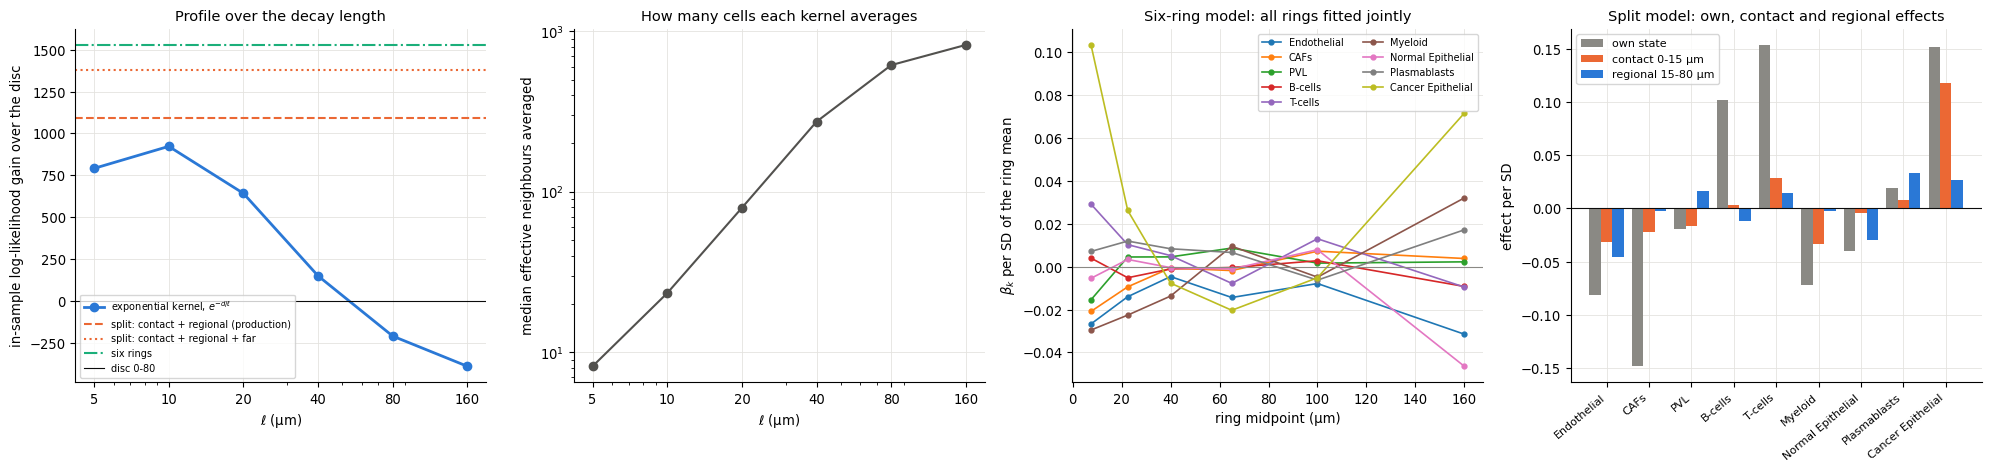

In [26]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8))
ax = axes[0]
ax.plot(ELLS, [nbr_tab.loc[m, "gain vs disc"] for m in exp_names], "o-", color=COL["real"], lw=2,
        label=r"exponential kernel, $e^{-d/\ell}$")
for m, ls, c in ((SPLIT, "--", COL["decoy"]), ("split: contact + regional + far", ":", COL["decoy"]),
                 ("six rings", "-.", COL["alt"])):
    ax.axhline(nbr_tab.loc[m, "gain vs disc"], ls=ls, color=c, lw=1.5,
               label=m + (" (production)" if m == SPLIT else ""))
ax.axhline(0, color=INK, lw=0.8, label="disc 0-80")
ax.set_xscale("log"); ax.set_xticks(ELLS); ax.set_xticklabels([f"{e:.0f}" for e in ELLS])
ax.set_xlabel(r"$\ell$ (µm)"); ax.set_ylabel("in-sample log-likelihood gain over the disc")
ax.set_title("Profile over the decay length"); ax.legend(fontsize=7)
ax = axes[1]
ax.plot(ELLS, [neff[e] for e in ELLS], "o-", color=COL["base"])
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xticks(ELLS); ax.set_xticklabels([f"{e:.0f}" for e in ELLS])
ax.set_xlabel(r"$\ell$ (µm)"); ax.set_ylabel("median effective neighbours averaged"); ax.set_title("How many cells each kernel averages")
ax = axes[2]
for t in TYPES:
    ax.plot(mid, prof.loc[t], "o-", ms=3.5, lw=1.2, label=t)
ax.axhline(0, color=MUTED, lw=0.8); ax.set_xlabel("ring midpoint (µm)"); ax.set_ylabel(r"$\beta_k$ per SD of the ring mean")
ax.set_title("Six-ring model: all rings fitted jointly"); ax.legend(fontsize=7, ncol=2)
ax = axes[3]
xx = np.arange(len(TYPES)); w = 0.27
ax.bar(xx - w, split_tab["own (per SD)"], w, color=MUTED, label="own state")
ax.bar(xx, split_tab["contact"], w, color=COL["decoy"], label="contact 0-15 µm")
ax.bar(xx + w, split_tab["regional"], w, color=COL["real"], label="regional 15-80 µm")
ax.axhline(0, color=INK, lw=0.8); ax.set_xticks(xx); ax.set_xticklabels(TYPES, rotation=40, ha="right", fontsize=8)
ax.set_ylabel("effect per SD"); ax.set_title("Split model: own, contact and regional effects"); ax.legend(fontsize=8)
fig.tight_layout(); savefig(fig, "neighbourhood_models")

### Spatial cross-validation

Five folds of contiguous blocks, from the stored fold map. Each model is refit
on four folds, warm-started from its full-data fit, and scored on the fifth.
Five candidates are compared:
- no neighbour block;
- the disc;
- the two-block split (production);
- the best exponential kernel;
- the six-ring model.

The table gives the total held-out log-likelihood gain over the disc,
summed over all held-out cells, with the per-fold gains and a paired t across
folds. With five folds the t is a rough guide, so read it together with how
consistent the per-fold signs are.

In [27]:
fm = pd.read_parquet("outputs/division_classifier/folds.parquet")
assert (fm["cell_id"].astype(str).to_numpy() == df["cell_id"].astype(str).to_numpy()).all()
foldA = fm["fold"].to_numpy()[A]
print("fold sizes within the annulus set:", np.bincount(foldA).tolist())
CV = {"none": nbb.subset(D, A, nbr=np.zeros((len(A), 8))), DISC: nbb.subset(D, A, nbr=NBR[DISC]),
      SPLIT: nbb.subset(D, A, nbr=NBR[SPLIT]),
      BEST_EXP: nbb.subset(D, A, nbr=NBR[BEST_EXP]), "six rings": nbb.subset(D, A, nbr=NBR["six rings"])}
CVTAG = {"none": "none", **{k: TAG[k] for k in CV if k in TAG}}
cv_rows = []
for name, DD in CV.items():
    for fo_ in range(5):
        tr, te = np.flatnonzero(foldA != fo_), np.flatnonzero(foldA == fo_)
        g = nbb.cached(f"cv_{CVTAG[name]}_f{fo_}", lambda DD=DD, tr=tr, name=name: nbb.fit(
            nbb.subset(DD, tr), init=nbr_fit[name]["params"], se=False, **BASE, **PEN))
        ll = nbb.heldout_loglik(g, nbb.subset(DD, te))
        cv_rows.append({"model": name, "fold": fo_, "n_test": len(te), "heldout": ll.sum(),
                        "converged": g["info"]["converged"]})
cvd = pd.DataFrame(cv_rows)
piv = cvd.pivot(index="fold", columns="model", values="heldout")
gain = piv.sub(piv[DISC], axis=0)
cv_tab = pd.DataFrame({"total held-out gain vs disc": gain.sum(),
                       "per-fold gains": gain.apply(lambda s: " / ".join(f"{v:+.0f}" for v in s)),
                       "paired t": gain.mean() / (gain.std(ddof=1) / np.sqrt(5)),
                       "folds better than disc": (gain > 0).sum()})
cv_tab.loc[DISC, ["paired t"]] = np.nan
print(f"all CV fits converged: {cvd['converged'].all()}")
cvd.to_csv(OUT / "neighbourhood_cv.csv", index=False)
cv_tab.sort_values("total held-out gain vs disc")

fold sizes within the annulus set: [113782, 100914, 113359, 107475, 103829]


all CV fits converged: True


,total held-out gain vs disc,per-fold gains,paired t,folds better than disc
model,,,,
none,-2113.6753,-440 / -492 / -424 / -317 / -440,-14.6318,0
disc 0-80,0.0000,+0 / +0 / +0 / +0 / +0,NaN,0
"exp, ell = 10",933.3770,+177 / +189 / +196 / +195 / +175,41.9927,5
split: contact + regional,1036.7405,+251 / +210 / +171 / +194 / +212,15.8036,5
six rings,1231.5335,+322 / +212 / +213 / +203 / +282,10.3803,5


### Reading §5

**A short-range neighbourhood beats the uniform disc out of sample, on every
fold.**

| neighbourhood | parameters vs disc | held-out gain over the disc |
|---|---|---|
| none | −32 | −2,114 (worse on 5/5) |
| exponential kernel, $\ell$ = 10 µm (≈23 effective neighbours) | 0 | +933 (better on 5/5) |
| split: contact 0–15 + regional 15–80 µm (production) | +32 | +1,037 (5/5) |
| six rings | +160 | +1,232 (5/5) |

These are the first run's gains within ±75 units, under the final weight model.

- **The kernel profile peaks at $\ell$ = 10 µm.** From 80 µm upward it is worse
  than the disc.
- **The six-ring fit shows two scales.** The contact ring dominates
  (‖β‖ 0.118 per SD), and 15–30 µm adds a little in the same direction
  (cosine 0.85). The 30–120 µm rings add almost nothing (0.02–0.03), and the
  120–200 µm ring returns (0.099, mostly Cancer Epithelial).
- **In the split model,** the contact block carries Cancer Epithelial (0.118
  per SD) and T-cells (0.029). The regional block carries Plasmablasts (0.033),
  and Endothelial (−0.046) and Normal Epithelial (−0.030) regions lower the rate.
- **A caution.** Contact effects correlate +0.78 with own-state effects across
  cell types (regional +0.48). Transcript spillover would do this, and so would
  proliferating cells clustering next to their own kind.

**Decision (user, 2026-10-07): the mixture's neighbour block is the
contact/regional split.** It isolates the spillover-prone contact signal in its
own block, so the regional block keeps its meaning as neighbourhood
composition. The rerun under the final weight model confirms it.

## 6. Summary

| question | old notebook (SpaNorm scores) | this table, final weight model | decision |
|---|---|---|---|
| depth: offset or free | $\theta \approx 0.70$, free it | $\hat\theta$ = 1.021 ± 0.004; spline and per-type departures are not purely technical | offset (θ = 1) |
| state-dependent dispersion | helps | LR 283 on 8 df; misfit −7%; PIT slightly worse | constant α in the baseline |
| does the oxygen source mark vessels? | AUROC 0.515 | 0.985 (source), 0.79 ($u$) | — |
| does $u$ explain division beyond state? | z ≈ +15, ~13× the decoy | $|\psi| \le 0.017$ per SD; leads its decoys only at $L_0$ = 50 µm | oxygen dropped |
| annulus, count-matched | decays more slowly than $\rho_\phi$ | decays with $\rho_\phi$; contact ring most informative | — |
| neighbourhood structure | — | split +1,037, $\ell$ = 10 µm kernel +933, six rings +1,232 held out | contact/regional split |

This is the rerun under the final weight model (2026-10-08). Every conclusion
of the first run (2026-10-06, earlier weight model) stands. Two numbers moved:
the free depth exponent (1.0005 to 1.021) and the sign of the short-range
oxygen effect (−0.010 to +0.014 per SD), neither large enough to change a
decision. What changed in the penalty and its selection, and why, is set out in
the [specification decisions document](https://claude.ai/code/artifact/70c686de-ba2d-4b2d-8d17-f29b5e2c2077).